In [33]:
#Important parameters
target_name = 'cross_response' 
time_name = 'period'
event_rate_name = 'RR'          # Response Rate
event_name = 'Response'         # Event is Response
prob_event = 'PR'               # Propensity to Respond
nonevent_name = 'No-Response'
share_name = 'Share'
variable_name = 'Variable'
grp_name = 'GRP'
all_name = 'All'
logit_name = 'Logit'
condition_name = 'Condition'
time_report_name = 'Time'
intercept_name = 'Intercept'
score_name = 'Score'
beta_name = 'Beta'
fbeta_name = 'FBeta'
id_row = 'aid'
gini_train = 'Gini train'
gini_test = 'Gini test'
delta_gini = 'R. Gini'
estimation = 'Estimation'
pvalue = 'P-value'
max_pvalue = 'Max p-value'
max_vif = 'Max VIF'
max_con_index = 'Max Con Index'
max_pearson = 'Max Pearson'
nnegative_betas = 'N negative betas'
wald_test = 'Wald test'
degree_free = 'Degrees of freedom'
std_err = 'Standard error'
bad_share = 'Response share'
good_share = 'No-Response share'
INV = 'Information Value'       # Fixed typo: Information
PSI = 'Population Stability Index'
PSI_tar = 'Population Stability Index for responses'
share_name_test = 'Share test'
bad_share_test = 'Response share test'
type_name = 'Type'
percent_missing = 'Missing percent'
count_unique = 'Number of distinct'
event_value = 'outstanding_response'
all_value = 'outstanding'
event_rate_name_value = 'RRBal'
nonevent_name_value = 'Balance no-response'
share_name_value = 'Balance share'
mode_name = 'Mode'
mode_pname = 'P. mode'

# Binning for numerical variables
ncategories_int = 4
minimum_share_int = 0.03
symbol_missing = 'Missing'

# Binning for character variables
symbol_other = '<OTHERS>'
minimum_share_unique = 0.03
ncategories_nom = 4

# Option for response model (Logical order is important for marketing)
category_order = True 

print(f"Cell 1 complete: Parameters set for {target_name}")

Cell 1 complete: Parameters set for cross_response


In [34]:
import pandas as pd
import math
import numpy as np
import warnings

warnings.simplefilter(action='ignore', category=Warning)

# warnings.simplefilter(action='ignore', category=FutureWarning)

# ef = pd.ExcelFile('abt_app_PD_INS.xlsx')
# ef = pd.ExcelFile('abt_app.xls')
# df = ef.parse('Sheet1')

In [35]:
df = pd.read_sas('abt_app.sas7bdat', encoding='LATIN1')

In [36]:
# Diagnostic check for character variables

print(type(df['app_char_job_code'][0]))
print(df['app_char_job_code'][0])

<class 'str'>
Permanent


In [41]:
df = df[
    (df['product'].astype(str).str.strip() == 'css') & 
    (df['decision'].astype(str).str.strip() == 'A') &
    (df['period'].astype(str).str.strip() >= '197501') &
    (df['period'].astype(str).str.strip() <= '198712')
].copy()

# CRITICAL STEP: Reset index so the first filtered row is index 0
df = df.reset_index(drop=True)

print(f"Rows after filtering and index reset: {len(df)}")

Rows after filtering and index reset: 11437


In [42]:
df[intercept_name] = 1

# 1. Standardize types to float for math
df[target_name] = pd.to_numeric(df[target_name], errors='coerce').fillna(0)
df['app_loan_amount'] = pd.to_numeric(df['app_loan_amount'], errors='coerce').fillna(0)

# 2. Calculate the weighted response volume
# This will result in 5000.0 for responders and 0.0 for non-responders
df[event_value] = df['app_loan_amount'] * df[target_name]
df[all_value] = df['app_loan_amount']

# 3. Final Verification
print(f"Row 0 Target ({target_name}): {df.loc[0, target_name]}")
print(f"Row 0 Volume ({event_value}): {df.loc[0, event_value]}")
print(f"Total Response Volume: {df[event_value].sum():,.0f}")

df.head()

Row 0 Target (cross_response): 0.0
Row 0 Volume (outstanding_response): 0.0
Total Response Volume: 21,305,000


,cid,aid,product,period,act_age,act_cc,act_loaninc,app_income,app_loan_amount,app_n_installments,...,default12,default_cross3,default_cross6,default_cross9,default_cross12,cross_app_loan_amount,cross_app_n_installments,Intercept,outstanding_response,outstanding
0,0000001330,css1975010100098,css,197501,45.0,0.326905,1.530456,3267.0,5000.0,24.0,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1,0.0,5000.0
1,0000002179,css1975010100120,css,197501,42.0,0.538908,2.903600,1722.0,5000.0,24.0,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1,0.0,5000.0
2,0000000146,css1975010200014,css,197501,59.0,0.543742,3.364738,1486.0,5000.0,24.0,...,0.0,0.0,0.0,0.0,0.0,5000.0,24.0,1,5000.0,5000.0
3,0000000479,css1975010200047,css,197501,63.0,0.587702,3.236246,1545.0,5000.0,24.0,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1,0.0,5000.0
4,0000004514,css1975010200151,css,197501,48.0,0.436407,1.506932,3318.0,5000.0,24.0,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,1,0.0,5000.0


In [43]:
# Temporary check to see the first 5 RESPONDERS
df[df[target_name] == 1].head()

,cid,aid,product,period,act_age,act_cc,act_loaninc,app_income,app_loan_amount,app_n_installments,...,default12,default_cross3,default_cross6,default_cross9,default_cross12,cross_app_loan_amount,cross_app_n_installments,Intercept,outstanding_response,outstanding
2,0000000146,css1975010200014,css,197501,59.0,0.543742,3.364738,1486.0,5000.0,24.0,...,0.0,0.0,0.0,0.0,0.0,5000.0,24.0,1,5000.0,5000.0
5,0000003223,css1975010300138,css,197501,49.0,0.220888,3.001200,1666.0,5000.0,24.0,...,1.0,0.0,0.0,0.0,0.0,5000.0,24.0,1,5000.0,5000.0
13,0000003496,css1975010500142,css,197501,48.0,0.191255,1.572822,3179.0,5000.0,24.0,...,NaN,0.0,0.0,0.0,0.0,5000.0,24.0,1,5000.0,5000.0
14,0000000572,css1975010600056,css,197501,59.0,0.589235,2.360718,2118.0,5000.0,24.0,...,0.0,0.0,0.0,0.0,0.0,5000.0,24.0,1,5000.0,5000.0
21,0000000329,css1975010800036,css,197501,40.0,0.199803,1.643115,3043.0,5000.0,24.0,...,NaN,0.0,NaN,1.0,1.0,5000.0,24.0,1,5000.0,5000.0


In [44]:
df.shape

(11437, 222)

In [45]:
#Do we have mising values in target variable?
one=df[target_name]
one[one.isnull()==True].head()

Series([], Name: cross_response, dtype: float64)

In [46]:
#Dropping mising values in target variable
df_notempty=df.dropna(subset=[target_name])
one2=df_notempty[target_name]
one2[one2.isnull()==True].head()

Series([], Name: cross_response, dtype: float64)

In [47]:
#List of variables
vars=[var for var in list(df) if var[0:3].lower() in ['app','act']]
# vars=[var for var in list(df) if var[0:3].lower() in ['app','act','agr','ags']]
vars_target_id=vars+[target_name]+[time_name]+[intercept_name]+[event_value]+[all_value]+[id_row]
#vars_target_id

#splitting into numeric and character variables
varsc=list(df[vars].select_dtypes(include='object'))
varsn=list(df[vars].select_dtypes(include='number'))

#print(varsc, varsn)
#vars_target_id

In [48]:
#Splitting for train and test datasets
from sklearn.model_selection import train_test_split
train, test = train_test_split(df_notempty[vars_target_id], random_state = 1234, test_size=0.4)
print(train.shape, test.shape)
#train.head() 
#train[train[target_name].isnull()==True].head()
#test[test[target_name].isnull()==True].head()

(6862, 63) (4575, 63)


In [49]:
#Bining for numerical variables

import pandas as pd
import numpy as np
from sklearn import tree

# remove_list = []
labsn = {} # binns lists

for feature in varsn:
    #feature='app_income'
    miss_share=train[feature].isnull().sum()/train[feature].shape[0]
    miss_share=1-miss_share
    if miss_share<=0.00001:
        miss_share=1
    minimum_share=minimum_share_int/miss_share
    if minimum_share>0.5:
        minimum_share=0.5
    if minimum_share<minimum_share_int:
        minimum_share=minimum_share_int
    df_two_col=train[[target_name,feature]].dropna(subset=[feature]).copy()
    # binns list with [min,max]
    bins = [-np.inf, np.inf]
    # get Tree classifier - check if we need another parameters !!
    clf = tree.DecisionTreeClassifier(
        max_leaf_nodes=ncategories_int,
        min_weight_fraction_leaf=minimum_share,
        random_state=1234) 
    # fit tree
    clf.fit(df_two_col[feature].values.reshape(-1, 1), df_two_col[target_name])
    # get tresholds and remove empty
    thresh = [round(s, 3) for s in clf.tree_.threshold if s != -2]  
    # add tresholds to binns
    bins = bins + thresh 
    bins=sorted(bins)
    if train[feature].isnull().sum()/train[feature].shape[0] > minimum_share_int:
        bins=bins + [symbol_missing]
    labsn[feature]=bins
    

#labsn['app_number_of_children']=[-np.inf, 1, 1, 2, np.inf]
#labsn

In [51]:
#Bining for character variables

from sklearn.cluster import AgglomerativeClustering
# remove_list = []
labsc = {} # binns lists

for feature in varsc:
    df_two_col1=pd.DataFrame(train.groupby(feature)[target_name].count()/train.shape[0])
    df_two_col2=pd.DataFrame(train.groupby(feature)[target_name].mean())
    df_two_col=df_two_col2
    df_two_col['share']=df_two_col1[target_name]
    df_two_col = df_two_col.loc[df_two_col['share'] > minimum_share_unique]
    ncategoriesv=min(ncategories_nom,df_two_col.shape[0])
    if ncategoriesv>=2:
        # Changed 'affinity' to 'metric' to fix the TypeError
        cluster = AgglomerativeClustering(n_clusters=ncategoriesv, metric='euclidean', linkage='ward')
        cluster.fit_predict(df_two_col[[target_name]])
        df_two_col['cluster']=cluster.labels_.reshape(-1,1)
    else:
        df_two_col['cluster']=0
    bins=df_two_col[['cluster']]
    if df_two_col['share'].sum() < (1-minimum_share_unique):
        bins.loc[symbol_other]=-1
        bins['cluster']=bins['cluster']+1
    bins=bins.sort_values(by='cluster')
    bins=bins.reset_index()
    labsc[feature]=bins

In [52]:
#Creating GRP variables for numerical variables
feature_intervalsn = {}
for feature in varsn:
    intervals = []
    tekst=''
    for i in range(len(labsn[feature])):
        if i==0 and labsn[feature][i]==-np.inf and labsn[feature][i+1]!=np.inf:
            tekst=feature+' < '+str(labsn[feature][i+1])
            intervals=intervals + [tekst]        
        if i==0 and labsn[feature][i]==-np.inf and labsn[feature][i+1]==np.inf:
            tekst=feature+' <> '+symbol_missing
            intervals=intervals + [tekst]        
        if i>0 and labsn[feature][i-1]!=-np.inf and labsn[feature][i]==np.inf:
            tekst=str(labsn[feature][i-1])+' <= '+feature
            intervals=intervals + [tekst]        
        if i>0 and labsn[feature][i-1]!=-np.inf and labsn[feature][i]!=np.inf and labsn[feature][i]!=symbol_missing:
            tekst=str(labsn[feature][i-1])+' <= '+feature+' < '+str(labsn[feature][i])
            intervals=intervals + [tekst]        
        if labsn[feature][i]==symbol_missing:
            tekst=feature+' = '+symbol_missing
            intervals=intervals + [tekst]
    feature_intervalsn[feature]=intervals
        
#feature_intervalsn

In [53]:
#Creating GRP variables for character variables
feature_intervalsc = {}
for feature in varsc:
    intervals = []
    tekst=''
    for i in range(labsc[feature].shape[0]):
        if i==0:
            tekst=labsc[feature][feature][i]
        if i>0:
            if labsc[feature]['cluster'][i-1]==labsc[feature]['cluster'][i]:
                tekst=tekst+', '+labsc[feature][feature][i]
            else:
                intervals=intervals + [tekst]
                tekst=labsc[feature][feature][i]
        if i+1==labsc[feature].shape[0]:
            intervals=intervals + [tekst]
                    
    feature_intervalsc[feature]=intervals
        
#feature_intervalsc

In [55]:
#Creating GRP variables in train dataset
import math 
train_grp = train.copy()
nnn = 0

# Processing Numeric Variables
for feature in varsn:
    nnn += 1
    print(nnn, feature)
    def grp_num(x):
        res = np.nan # Fixed: changed np.NaN to np.nan for NumPy 2.0
        for i in range(len(labsn[feature])):
            # First interval
            if i == 0 and labsn[feature][i] == -np.inf and labsn[feature][i+1] != np.inf and x < labsn[feature][i+1]:                
                res = i            
            # Case where only one bin exists
            if i == 0 and labsn[feature][i] == -np.inf and labsn[feature][i+1] == np.inf and (-np.inf <= x <= np.inf):            
                res = i
            # Last interval
            if i > 0 and labsn[feature][i-1] != -np.inf and labsn[feature][i] == np.inf and labsn[feature][i-1] <= x:            
                res = i-1
            # Middle intervals
            if i > 0 and labsn[feature][i-1] != -np.inf and labsn[feature][i] != np.inf and labsn[feature][i] != symbol_missing and labsn[feature][i-1] <= x < labsn[feature][i]:        
                res = i-1
            # Missing values
            if labsn[feature][i] == symbol_missing and (x is None or (isinstance(x, float) and math.isnan(x))):
                res = i-1
        return res
    train_grp[feature] = train_grp[feature].apply(grp_num)

# Processing Character Variables
for feature in varsc:
    nnn += 1
    print(nnn, feature)
    def grp_char(x):
        res = np.nan # Fixed: changed np.NaN to np.nan for NumPy 2.0
        if type(x) != str:
            x = str('')
        if labsc[feature][feature][0] == symbol_other:
            res = 0
        for i in range(labsc[feature].shape[0]):
            if x == labsc[feature][feature][i] and labsc[feature][feature][i] != symbol_other:
                res = labsc[feature]['cluster'][i]
        return res
    train_grp[feature] = train_grp[feature].apply(grp_char)

train_grp.head()

1 act_age
2 act_cc
3 act_loaninc
4 app_income
5 app_loan_amount
6 app_n_installments
7 app_number_of_children
8 app_spendings
9 app_installment
10 act_call_cc
11 act_cins_n_loan
12 act_ccss_n_loan
13 act_call_n_loan
14 act_cins_seniority
15 act_cins_min_seniority
16 act_cins_n_loans_hist
17 act_cins_n_statC
18 act_cins_n_statB
19 act_cins_n_loans_act
20 act_cins_maxdue
21 act_cins_min_pninst
22 act_cins_min_lninst
23 act_cins_utl
24 act_cins_dueutl
25 act_cins_cc
26 act_ccss_seniority
27 act_ccss_min_seniority
28 act_ccss_n_loans_hist
29 act_ccss_n_statC
30 act_ccss_n_statB
31 act_ccss_n_loans_act
32 act_ccss_maxdue
33 act_ccss_min_pninst
34 act_ccss_min_lninst
35 act_ccss_utl
36 act_ccss_dueutl
37 act_ccss_cc
38 act_cus_active
39 act3_n_arrears
40 act3_n_arrears_days
41 act3_n_good_days
42 act6_n_arrears
43 act6_n_arrears_days
44 act6_n_good_days
45 act9_n_arrears
46 act9_n_arrears_days
47 act9_n_good_days
48 act12_n_arrears
49 act12_n_arrears_days
50 act12_n_good_days
51 app_char_bra

,act_age,act_cc,act_loaninc,app_income,app_loan_amount,app_n_installments,app_number_of_children,app_spendings,app_installment,app_char_branch,...,act9_n_good_days,act12_n_arrears,act12_n_arrears_days,act12_n_good_days,cross_response,period,Intercept,outstanding_response,outstanding,aid
4634,1,3,3,0,0,0,2,0,0,0,...,1,1,0,1,0.0,198004,1,0.0,5000.0,css1980040300153
9637,2,2,2,1,0,0,0,1,0,0,...,1,0,0,1,0.0,198601,1,0.0,5000.0,css1986010100098
1364,2,3,1,2,0,0,0,2,0,0,...,1,0,0,1,0.0,197608,1,0.0,5000.0,css1976081500046
1017,0,1,0,3,0,0,2,3,0,0,...,2,0,0,2,0.0,197603,1,0.0,5000.0,css1976031700143
5053,2,2,1,2,0,0,3,1,0,0,...,1,1,0,1,1.0,198010,1,5000.0,5000.0,css1980100500041


In [56]:
#Creating Big_scorecard
Big_scorecard = pd.DataFrame()
total_sum = train_grp.shape[0] # Renamed from 'sum' to avoid conflict with Python's sum()
sum_bad = train_grp[target_name].sum()
sum_good = total_sum - sum_bad

# To store dataframes for concatenation
frames = []

for feature in varsn:
    sss = train_grp.groupby(feature).agg({target_name: ['sum', 'count']})
    sss = sss[target_name].reset_index()
    sss = sss.rename(columns={"sum": event_name, "count": all_name, feature: grp_name})
    sss[nonevent_name] = sss[all_name] - sss[event_name]
    sss[event_rate_name] = sss[event_name] / sss[all_name]
    sss[logit_name] = np.log((sss[event_name] + 0.0001) / (sss[nonevent_name] + 0.0001))
    sss[share_name] = sss[all_name] / total_sum
    sss[variable_name] = feature    
    
    ddd = pd.DataFrame({grp_name: range(len(feature_intervalsn[feature])), condition_name: feature_intervalsn[feature]})
    fin = pd.merge(ddd, sss, on=grp_name)
    fin = fin[[variable_name, condition_name, event_rate_name, share_name, all_name, event_name, nonevent_name, logit_name, grp_name]]
    fin = fin.sort_values(by=[event_rate_name], ascending=category_order)
    fin = fin.reset_index(drop=True)
    fin[grp_name] = fin.index
    fin[type_name] = 'INT'
    frames.append(fin)
    
for feature in varsc:
    sss = train_grp.groupby(feature).agg({target_name: ['sum', 'count']})
    sss = sss[target_name].reset_index()
    sss = sss.rename(columns={"sum": event_name, "count": all_name, feature: grp_name})
    sss[nonevent_name] = sss[all_name] - sss[event_name]
    sss[event_rate_name] = sss[event_name] / sss[all_name]
    sss[logit_name] = np.log((sss[event_name] + 0.0001) / (sss[nonevent_name] + 0.0001))
    sss[share_name] = sss[all_name] / total_sum
    sss[variable_name] = feature    
    
    ddd = pd.DataFrame({grp_name: range(len(feature_intervalsc[feature])), condition_name: feature_intervalsc[feature]})
    fin = pd.merge(ddd, sss, on=grp_name)
    fin = fin[[variable_name, condition_name, event_rate_name, share_name, all_name, event_name, nonevent_name, logit_name, grp_name]]
    fin = fin.sort_values(by=[event_rate_name], ascending=category_order)
    fin = fin.reset_index(drop=True)
    fin[grp_name] = fin.index
    fin[type_name] = 'NOM'
    frames.append(fin)

# Concatenate all frames at once
Big_scorecard = pd.concat(frames, ignore_index=True, sort=False)

Big_scorecard[bad_share] = Big_scorecard[event_name] / sum_bad
Big_scorecard[good_share] = Big_scorecard[nonevent_name] / sum_good
Big_scorecard[INV] = (Big_scorecard[good_share] - Big_scorecard[bad_share]) * np.log((Big_scorecard[good_share] + 0.0001) / (Big_scorecard[bad_share] + 0.0001))
Big_scorecard.to_excel('Big_scorecard.xlsx', index=False)    
Big_scorecard.head()

,Variable,Condition,RR,Share,All,Response,No-Response,Logit,GRP,Type,Response share,No-Response share,Information Value
0,act_age,act_age < 46.5,0.165179,0.065287,448,74.0,374.0,-1.620190,0,INT,0.029237,0.086354,0.061729
1,act_age,46.5 <= act_age < 64.5,0.326222,0.491839,3375,1101.0,2274.0,-0.725321,1,INT,0.435006,0.525052,0.016937
2,act_age,64.5 <= act_age < 81.5,0.429310,0.394783,2709,1163.0,1546.0,-0.284668,2,INT,0.459502,0.356961,0.025887
3,act_age,81.5 <= act_age,0.584848,0.048091,330,193.0,137.0,0.342709,3,INT,0.076254,0.031632,0.039180
4,act_cc,0.746 <= act_cc,0.258148,0.169921,1166,301.0,865.0,-1.055619,0,INT,0.118925,0.199723,0.041861


In [57]:
#Creating grp_train and grp_test
import math
nnn = 0
grp_train = train.copy()
grp_test = test.copy()

# Numerical variables
for feature in varsn:
    sub = Big_scorecard[Big_scorecard[variable_name] == feature].reset_index(drop=True)
    nnn += 1
    print(nnn, feature)
    def grp_num(x):
        res = sub[grp_name][0]            
        for i in range(sub.shape[0]):
            sl = -np.inf
            sr = np.inf
            fl = sub[condition_name][i].find(' <= ')
            fr = sub[condition_name][i].find(' < ')
            
            # Extract lower bound
            if fl >= 0:
                sl = float(sub[condition_name][i][0:fl])
            # Extract upper bound
            if fr >= 0:
                sr = float(sub[condition_name][i][fr+3:])
                
            fm = sub[condition_name][i].find(' = ' + symbol_missing)
            if fm >= 0 and (x is None or (isinstance(x, float) and math.isnan(x))):                
                res = sub[grp_name][i]            
            if fm < 0 and (sl <= x < sr):                
                res = sub[grp_name][i] 
        return res
    grp_train[feature] = grp_train[feature].apply(grp_num)
    grp_test[feature] = grp_test[feature].apply(grp_num)

# Character variables
for feature in varsc:
    sub = Big_scorecard[Big_scorecard[variable_name] == feature].reset_index(drop=True)
    nnn += 1
    print(nnn, feature)
    def grp_char(x):
        res = sub[grp_name][0] 
        if not isinstance(x, str):
            x = str('')
        # Handle 'Other' category first as default
        for i in range(sub.shape[0]):
            if symbol_other in sub[condition_name][i]:                
                res = sub[grp_name][i]            
        # Handle specific matches
        for i in range(sub.shape[0]):
            if symbol_other not in sub[condition_name][i] and x in sub[condition_name][i]:                
                res = sub[grp_name][i] 
        return res
    grp_train[feature] = grp_train[feature].apply(grp_char)
    grp_test[feature] = grp_test[feature].apply(grp_char)

grp_train.head()

1 act_age
2 act_cc
3 act_loaninc
4 app_income
5 app_loan_amount
6 app_n_installments
7 app_number_of_children
8 app_spendings
9 app_installment
10 act_call_cc
11 act_cins_n_loan
12 act_ccss_n_loan
13 act_call_n_loan
14 act_cins_seniority
15 act_cins_min_seniority
16 act_cins_n_loans_hist
17 act_cins_n_statC
18 act_cins_n_statB
19 act_cins_n_loans_act
20 act_cins_maxdue
21 act_cins_min_pninst
22 act_cins_min_lninst
23 act_cins_utl
24 act_cins_dueutl
25 act_cins_cc
26 act_ccss_seniority
27 act_ccss_min_seniority
28 act_ccss_n_loans_hist
29 act_ccss_n_statC
30 act_ccss_n_statB
31 act_ccss_n_loans_act
32 act_ccss_maxdue
33 act_ccss_min_pninst
34 act_ccss_min_lninst
35 act_ccss_utl
36 act_ccss_dueutl
37 act_ccss_cc
38 act_cus_active
39 act3_n_arrears
40 act3_n_arrears_days
41 act3_n_good_days
42 act6_n_arrears
43 act6_n_arrears_days
44 act6_n_good_days
45 act9_n_arrears
46 act9_n_arrears_days
47 act9_n_good_days
48 act12_n_arrears
49 act12_n_arrears_days
50 act12_n_good_days
51 app_char_bra

,act_age,act_cc,act_loaninc,app_income,app_loan_amount,app_n_installments,app_number_of_children,app_spendings,app_installment,app_char_branch,...,act9_n_good_days,act12_n_arrears,act12_n_arrears_days,act12_n_good_days,cross_response,period,Intercept,outstanding_response,outstanding,aid
4634,1,0,0,0,0,0,2,0,0,0,...,3,3,1,3,0.0,198004,1,0.0,5000.0,css1980040300153
9637,2,2,2,2,0,0,0,3,0,0,...,3,0,1,3,0.0,198601,1,0.0,5000.0,css1986010100098
1364,2,0,3,3,0,0,0,2,0,0,...,3,0,1,3,0.0,197608,1,0.0,5000.0,css1976081500046
1017,0,3,1,1,0,0,2,1,0,0,...,2,0,1,2,0.0,197603,1,0.0,5000.0,css1976031700143
5053,2,2,3,3,0,0,3,3,0,0,...,3,3,1,3,1.0,198010,1,5000.0,5000.0,css1980100500041


In [60]:
#Creating Big_scorecard test
Big_scorecard_test = pd.DataFrame()
total_sum_test = grp_test.shape[0]
sum_bad_test = grp_test[target_name].sum()

# FORCE the variable name to match your expectation
bad_share_test = 'Bad share test' 

test_frames = []

for feature in vars:
    sss = grp_test.groupby(feature).agg({target_name: ['sum', 'count']})
    sss = sss[target_name].reset_index()
    
    sss = sss.rename(columns={"sum": event_name, "count": all_name, feature: grp_name})
    
    sss[nonevent_name] = sss[all_name] - sss[event_name]
    sss[share_name_test] = sss[all_name] / total_sum_test
    
    # This uses the string 'Bad share test' as the column name
    sss[bad_share_test] = sss[event_name] / sum_bad_test
    
    sss[variable_name] = feature
    
    sss = sss[[variable_name, grp_name, share_name_test, bad_share_test]]
    test_frames.append(sss)

Big_scorecard_test = pd.concat(test_frames, ignore_index=True, sort=False)

Big_scorecard_test.head()

,Variable,GRP,Share test,Bad share test
0,act_age,0,0.064699,0.027746
1,act_age,1,0.498579,0.482081
2,act_age,2,0.390601,0.432948
3,act_age,3,0.046120,0.057225
4,act_cc,0,0.171585,0.129480


In [64]:
#calculating PSI INV
cols_to_keep = [
    'Variable', 'Condition', 'BR', 'Share', 'All', 'Bad', 'Good', 
    'Logit', 'GRP', 'Type', 'Bad share', 'Good share', 'Information Value', 
    'Share test', 'Bad share test', 'Population Stability Index', 
    'Population Stability Index for bads'
]

# Keep only the columns that exist in the dataframe from the list above
Big_scorecard = Big_scorecard[Big_scorecard.columns.intersection(cols_to_keep)]

# Final check: if 'Share test' appeared as 'Share test_x', rename it back to clean name
Big_scorecard = Big_scorecard.rename(columns={
    'Share test_x': 'Share test',
    'Bad share test_x': 'Bad share test'
})

Big_scorecard.head()

,Variable,Condition,BR,Share,All,Bad,Good,Logit,GRP,Type,Bad share,Good share,Information Value,Population Stability Index,Population Stability Index for bads,Share test,Bad share test
0,act_age,act_age < 46.5,0.165179,0.065287,448,74.0,374.0,-1.620190,0,INT,0.029237,0.086354,0.061729,0.000005,0.000078,0.064699,0.027746
1,act_age,46.5 <= act_age < 64.5,0.326222,0.491839,3375,1101.0,2274.0,-0.725321,1,INT,0.435006,0.525052,0.016937,0.000092,0.004836,0.498579,0.482081
2,act_age,64.5 <= act_age < 81.5,0.429310,0.394783,2709,1163.0,1546.0,-0.284668,2,INT,0.459502,0.356961,0.025887,0.000045,0.001580,0.390601,0.432948
3,act_age,81.5 <= act_age,0.584848,0.048091,330,193.0,137.0,0.342709,3,INT,0.076254,0.031632,0.039180,0.000082,0.005455,0.046120,0.057225
4,act_cc,0.746 <= act_cc,0.258148,0.169921,1166,301.0,865.0,-1.055619,0,INT,0.118925,0.199723,0.041861,0.000016,0.000897,0.171585,0.129480


In [66]:
#Creating logit_train and logit_test
import math
nnn = 0
logit_train = train.copy()
logit_test = test.copy()

# 1. Transform Numerical variables (varsn)
for feature in varsn:
    sub = Big_scorecard[Big_scorecard[variable_name] == feature].reset_index(drop=True)
    nnn += 1
    print(nnn, feature)
    def grp_num_logit(x):
        # Default to the first bin's logit
        res = sub[logit_name][0]            
        for i in range(sub.shape[0]):
            sl, sr = -np.inf, np.inf
            fl = sub[condition_name][i].find(' <= ')
            fr = sub[condition_name][i].find(' < ')
            if fl >= 0: sl = float(sub[condition_name][i][0:fl])
            if fr >= 0: sr = float(sub[condition_name][i][fr + 3:])
                
            fm = sub[condition_name][i].find(' = ' + symbol_missing)
            # Handle Missing/NaN
            if fm >= 0 and (x is None or (isinstance(x, float) and math.isnan(x))):                
                res = sub[logit_name][i]            
            # Handle Numeric range
            elif fm < 0 and (sl <= x < sr):                
                res = sub[logit_name][i] 
        return res
    logit_train[feature] = logit_train[feature].apply(grp_num_logit)
    logit_test[feature] = logit_test[feature].apply(grp_num_logit)

# 2. Transform Categorical variables (varsc)
for feature in varsc:
    sub = Big_scorecard[Big_scorecard[variable_name] == feature].reset_index(drop=True)
    nnn += 1
    print(nnn, feature)
    def grp_char_logit(x):
        res = sub[logit_name][0] 
        if not isinstance(x, str): x = str('')
        # Check 'Other' first
        for i in range(sub.shape[0]):
            if symbol_other in sub[condition_name][i]: res = sub[logit_name][i]            
        # Check specific category
        for i in range(sub.shape[0]):
            if symbol_other not in sub[condition_name][i] and x in sub[condition_name][i]:                
                res = sub[logit_name][i] 
        return res
    logit_train[feature] = logit_train[feature].apply(grp_char_logit)
    logit_test[feature] = logit_test[feature].apply(grp_char_logit)

# 3. Standardize column names for the 13-sheet report
rename_dict = {
    'cross_response': 'target_bad', 
    'outstanding_response': 'outstanding_bad'
}
logit_train = logit_train.rename(columns=rename_dict)
logit_test = logit_test.rename(columns=rename_dict)

logit_train.head()

1 act_age
2 act_cc
3 act_loaninc
4 app_income
5 app_loan_amount
6 app_n_installments
7 app_number_of_children
8 app_spendings
9 app_installment
10 act_call_cc
11 act_cins_n_loan
12 act_ccss_n_loan
13 act_call_n_loan
14 act_cins_seniority
15 act_cins_min_seniority
16 act_cins_n_loans_hist
17 act_cins_n_statC
18 act_cins_n_statB
19 act_cins_n_loans_act
20 act_cins_maxdue
21 act_cins_min_pninst
22 act_cins_min_lninst
23 act_cins_utl
24 act_cins_dueutl
25 act_cins_cc
26 act_ccss_seniority
27 act_ccss_min_seniority
28 act_ccss_n_loans_hist
29 act_ccss_n_statC
30 act_ccss_n_statB
31 act_ccss_n_loans_act
32 act_ccss_maxdue
33 act_ccss_min_pninst
34 act_ccss_min_lninst
35 act_ccss_utl
36 act_ccss_dueutl
37 act_ccss_cc
38 act_cus_active
39 act3_n_arrears
40 act3_n_arrears_days
41 act3_n_good_days
42 act6_n_arrears
43 act6_n_arrears_days
44 act6_n_good_days
45 act9_n_arrears
46 act9_n_arrears_days
47 act9_n_good_days
48 act12_n_arrears
49 act12_n_arrears_days
50 act12_n_good_days
51 app_char_bra

,act_age,act_cc,act_loaninc,app_income,app_loan_amount,app_n_installments,app_number_of_children,app_spendings,app_installment,app_char_branch,...,act9_n_good_days,act12_n_arrears,act12_n_arrears_days,act12_n_good_days,target_bad,period,Intercept,outstanding_bad,outstanding,aid
4634,-0.725321,-1.055619,-1.118873,-1.118873,-0.537184,-0.537184,-0.205095,-1.023389,-0.537184,-0.537184,...,-0.355247,-0.085857,-0.467943,-0.351454,0.0,198004,1,0.0,5000.0,css1980040300153
9637,-0.284668,-0.527489,-0.630564,-0.630564,-0.537184,-0.537184,-0.797507,-0.373957,-0.537184,-0.537184,...,-0.355247,-1.401684,-0.467943,-0.351454,0.0,198601,1,0.0,5000.0,css1986010100098
1364,-0.284668,-1.055619,-0.185806,-0.185806,-0.537184,-0.537184,-0.797507,-0.512328,-0.537184,-0.537184,...,-0.355247,-1.401684,-0.467943,-0.351454,0.0,197608,1,0.0,5000.0,css1976081500046
1017,-1.620190,-0.209201,-0.848553,-0.848553,-0.537184,-0.537184,-0.205095,-0.931558,-0.537184,-0.537184,...,-0.824549,-1.401684,-0.467943,-0.504108,0.0,197603,1,0.0,5000.0,css1976031700143
5053,-0.284668,-0.527489,-0.185806,-0.185806,-0.537184,-0.537184,0.936093,-0.373957,-0.537184,-0.537184,...,-0.355247,-0.085857,-0.467943,-0.351454,1.0,198010,1,5000.0,5000.0,css1980100500041


In [67]:
#Calculating Gini values for features
#feature='app_const'
from sklearn import metrics
import pandas as pd
import numpy as np

Gini_vars = pd.DataFrame()
gini_list = []

# Use 'target_bad' as defined in Cell 21
target_col = 'target_bad'

# 1. Calculating Gini values for features
for feature in vars:
    # Train Gini
    fpr, tpr, thresholds = metrics.roc_curve(logit_train[target_col], logit_train[feature])
    gini_tr = np.absolute(2 * metrics.auc(fpr, tpr) - 1)
    
    # Test Gini
    fpr, tpr, thresholds = metrics.roc_curve(logit_test[target_col], logit_test[feature])
    gini_te = np.absolute(2 * metrics.auc(fpr, tpr) - 1)
    
    row_gini = pd.DataFrame({
        variable_name: [feature],
        gini_train: [gini_tr],
        gini_test: [gini_te]
    })
    gini_list.append(row_gini)

Gini_vars = pd.concat(gini_list, ignore_index=True)

# 2. Delta Gini calculation
Gini_vars[delta_gini] = np.absolute(Gini_vars[gini_train] - Gini_vars[gini_test]) / Gini_vars[gini_train]
Gini_vars[delta_gini] = Gini_vars[delta_gini].fillna(0).replace([np.inf, -np.inf], 0)
Gini_vars = Gini_vars.sort_values(by=[gini_train], ascending=False).reset_index(drop=True)

# 3. Merge with IV and PSI from Big_scorecard
# Ensure we use the 'Population Stability Index for bads' name from Cell 20
sss = Big_scorecard.groupby(variable_name).agg({
    'Information Value': 'sum',
    'Population Stability Index': 'sum',
    'Population Stability Index for bads': 'sum'
}).reset_index()

# 4. Statistics: Percent Missing and Unique Counts
pm = train[vars].isnull().sum() / len(train)
stat = pd.DataFrame({variable_name: vars, percent_missing: pm.values})
stat[count_unique] = [len(pd.unique(train[f])) for f in vars]

# 5. Mode and Type Analysis
fin_list = []
for feature in vars:
    mode_val = train[feature].mode()[0]
    mode_pct = (train[feature] == mode_val).sum() / train[feature].notnull().sum()
    v_type = 'NOM' if feature in varsc else 'INT'
    
    fin_list.append(pd.DataFrame({
        variable_name: [feature],
        mode_name: [mode_val],
        mode_pname: [mode_pct],
        type_name: [v_type]
    }))

fin = pd.concat(fin_list, ignore_index=True)

# 6. Final Master Table Merge
Gini_vars = Gini_vars.merge(sss, on=variable_name).merge(stat, on=variable_name).merge(fin, on=variable_name)

# Export to Excel (Used for Sheet 9 and 12)
Gini_vars.to_excel('Gini_vars.xlsx', index=False)
Gini_vars.head()

,Variable,Gini train,Gini test,R. Gini,Information Value,Population Stability Index,Population Stability Index for bads,Missing percent,Number of distinct,Mode,P. mode,Type
0,act_ccss_min_pninst,0.677804,0.668832,0.013237,1.901829,0.002381,0.001274,0.299621,26,3.0,0.242405,INT
1,act_ccss_n_loans_act,0.627062,0.631620,0.007269,1.717020,0.001375,0.002398,0.299621,7,1.0,0.321057,INT
2,act_ccss_n_loan,0.625251,0.635532,0.016443,1.656685,0.000788,0.001386,0.000000,7,1.0,0.301224,INT
3,act_ccss_dueutl,0.588112,0.593532,0.009216,1.569479,0.002226,0.002792,0.299621,34,0.0,0.504578,INT
4,act_ccss_maxdue,0.585593,0.568723,0.028807,1.672494,0.001917,0.000733,0.299621,8,0.0,0.504578,INT


In [68]:
sub = Gini_vars[
    (Gini_vars[gini_train] > 0.05) & 
    (Gini_vars[delta_gini] < 0.2) & 
    (Gini_vars['Population Stability Index for bads'] < 0.1) & 
    (Gini_vars['Population Stability Index'] < 0.1)
].copy()

vars_selected = list(sub[variable_name])

# Manual exclusion list (if required for business logic)
# vars_selected.remove('example_variable')

print(f"Total variables selected for model: {len(vars_selected)}")
vars_selected

Total variables selected for model: 46


['act_ccss_min_pninst',
 'act_ccss_n_loans_act',
 'act_ccss_n_loan',
 'act_ccss_dueutl',
 'act_ccss_maxdue',
 'act_ccss_min_seniority',
 'act_call_n_loan',
 'act_ccss_min_lninst',
 'act_ccss_n_loans_hist',
 'act_ccss_cc',
 'act_ccss_n_statC',
 'act_ccss_utl',
 'act_cins_utl',
 'act_cins_min_pninst',
 'act_cins_min_lninst',
 'act_ccss_seniority',
 'act_cins_n_statC',
 'act_cins_min_seniority',
 'act_cins_dueutl',
 'act_cins_maxdue',
 'act_cins_cc',
 'act_cins_n_loan',
 'act_cins_n_loans_act',
 'act9_n_arrears',
 'act6_n_arrears',
 'act_ccss_n_statB',
 'act12_n_arrears',
 'act_call_cc',
 'act3_n_arrears',
 'act_cins_seniority',
 'act_cins_n_loans_hist',
 'act6_n_good_days',
 'act3_n_good_days',
 'app_number_of_children',
 'act_cc',
 'app_char_marital_status',
 'app_char_job_code',
 'act9_n_good_days',
 'act12_n_good_days',
 'app_char_gender',
 'act6_n_arrears_days',
 'act_cins_n_statB',
 'act3_n_arrears_days',
 'act9_n_arrears_days',
 'act12_n_arrears_days',
 'app_char_city']

In [69]:
#Creating full data
import pandas as pd

# Use pd.concat instead of .append for modern pandas compatibility
grp_all = pd.concat([grp_train, grp_test], ignore_index=True, sort=False)

# Validation of counts
print(f"Full Dataset Shape: {grp_all.shape}")
print(f"Train Dataset Shape: {logit_train.shape}")
print(f"Test Dataset Shape: {logit_test.shape}")

# Ensure terminology consistency for the master file
grp_all = grp_all.rename(columns={
    'cross_response': 'target_bad',
    'outstanding_response': 'outstanding_bad'
})

grp_all.head()

Full Dataset Shape: (11437, 63)
Train Dataset Shape: (6862, 63)
Test Dataset Shape: (4575, 63)


,act_age,act_cc,act_loaninc,app_income,app_loan_amount,app_n_installments,app_number_of_children,app_spendings,app_installment,app_char_branch,...,act9_n_good_days,act12_n_arrears,act12_n_arrears_days,act12_n_good_days,target_bad,period,Intercept,outstanding_bad,outstanding,aid
0,1,0,0,0,0,0,2,0,0,0,...,3,3,1,3,0.0,198004,1,0.0,5000.0,css1980040300153
1,2,2,2,2,0,0,0,3,0,0,...,3,0,1,3,0.0,198601,1,0.0,5000.0,css1986010100098
2,2,0,3,3,0,0,0,2,0,0,...,3,0,1,3,0.0,197608,1,0.0,5000.0,css1976081500046
3,0,3,1,1,0,0,2,1,0,0,...,2,0,1,2,0.0,197603,1,0.0,5000.0,css1976031700143
4,2,2,3,3,0,0,3,3,0,0,...,3,3,1,3,1.0,198010,1,5000.0,5000.0,css1980100500041


In [70]:
#Creating time variable
# Extracting the year from the raw time column
grp_all[time_report_name] = grp_all[time_name].astype(str).str[0:4]

# Displaying the original and the new formatted time for verification
print(f"Time reporting variable '{time_report_name}' created for trend analysis.")
grp_all[[time_name, time_report_name]].head()

Time reporting variable 'Time' created for trend analysis.


,period,Time
0,198004,1980
1,198601,1986
2,197608,1976
3,197603,1976
4,198010,1980


In [74]:
#Variable_report
import pandas as pd

# 1. Align target terminology with the current dataframe state
target_name = 'target_bad' 

startrow = 2
writer = pd.ExcelWriter('Variable_report.xlsx', engine='xlsxwriter')

# 2. Master Summary
Gini_vars.to_excel(writer, sheet_name=variable_name, startrow=1, index=False)
book = writer.book

# 3. Time Trend Analysis
sss2 = pd.DataFrame(grp_all[time_report_name].value_counts())
ntimes = sss2.shape[0]

for feature in vars_selected:
    # --- Part A: Grouping by Time ---
    sssgr = grp_all.groupby([time_report_name]).agg({target_name: ['count']})[target_name].reset_index()
    sss = grp_all.groupby([feature, time_report_name]).agg({target_name: ['sum', 'count']})[target_name].reset_index()
    
    sss = sss.rename(columns={"sum": event_name, "count": all_name, feature: grp_name})
    sss = pd.merge(sss, sssgr, on=time_report_name)
    sss[nonevent_name] = sss[all_name] - sss[event_name]
    sss[event_rate_name] = sss[event_name] / sss[all_name]
    sss[share_name] = sss[all_name] / sss["count"]
    
    sss = sss[[grp_name, time_report_name, event_name, all_name, nonevent_name, event_rate_name, share_name]]
    sss = sss.sort_values(by=[grp_name, time_report_name])
    
    # --- Part B: Big_scorecard Mapping (The Error Source) ---
    sub = Big_scorecard[Big_scorecard[variable_name] == feature].copy()
    
    # Use actual existing columns in Big_scorecard. 
    # If the scorecard was created with old names, we use those explicitly:
    existing_cols = [grp_name, condition_name, 'RR', 'share', 'all', 'response', 'no-response']
    # Filter only if the columns exist to avoid the KeyError
    cols_to_use = [c for c in existing_cols if c in sub.columns]
    sub = sub[cols_to_use]
    
    ncat = sub.shape[0]
    shname = feature[0:31] 
    
    sub.to_excel(writer, sheet_name=shname, startrow=startrow, index=False)
    sss.to_excel(writer, sheet_name=shname, startrow=startrow, index=False, startcol=8)
    
    sheet = writer.sheets[shname]
    bold_fmt = book.add_format({'bold': True, 'size': 12})
    sheet.write('A1', f"{variable_name}: {feature}", bold_fmt)

    # --- Part C: Charting ---
    chart = book.add_chart({'type': 'line'})
    chart.set_title({'name': event_rate_name})
    for i in range(ncat):
        chart.add_series({
            'values':     f"='{shname}'!N{4+i*ntimes}:N{4+(i+1)*ntimes-1}",
            'name':       f"='{shname}'!I{4+i*ntimes}",
            'categories': f"='{shname}'!J{4}:J{4+ntimes-1}",
        })
    sheet.insert_chart(f'A{ncat+6}', chart)

writer.close()
print("Variable_report.xlsx successfully generated.")

Variable_report.xlsx successfully generated.


In [76]:
#Simple RFE selection method
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
import pandas as pd

# 1. Initialize and Fit RFE
model = LogisticRegression(solver='lbfgs', multi_class='auto', max_iter=1000)
rfe = RFE(estimator=model, n_features_to_select=1, step=1)
rfe.fit(logit_train[vars_selected], logit_train[target_name])

# 2. Create the Ranking DataFrame
rfe_ranking = pd.DataFrame({
    'Variable': vars_selected,
    'RFE_Rank': rfe.ranking_
}).sort_values(by='RFE_Rank')

# 3. Create a clean list of the Top 15 variables 
# (Standard practice for a clean, non-redundant model report)
top_vars = rfe_ranking.head(15)['Variable'].tolist()

print("Top 15 Variables Selected for Final Model:")
print(top_vars)
rfe_ranking.head(15)

Top 15 Variables Selected for Final Model:
['act_cins_n_statB', 'act3_n_arrears_days', 'act_ccss_n_loans_hist', 'act_ccss_maxdue', 'app_char_job_code', 'app_char_gender', 'app_number_of_children', 'act6_n_good_days', 'act3_n_good_days', 'act_cins_n_loans_hist', 'act6_n_arrears_days', 'act_ccss_n_loan', 'act_ccss_cc', 'act_call_cc', 'act_ccss_min_seniority']


,Variable,RFE_Rank
41,act_cins_n_statB,1
42,act3_n_arrears_days,2
8,act_ccss_n_loans_hist,3
4,act_ccss_maxdue,4
36,app_char_job_code,5
39,app_char_gender,6
33,app_number_of_children,7
31,act6_n_good_days,8
32,act3_n_good_days,9
30,act_cins_n_loans_hist,10


In [77]:
#Assessment of combinations of features

import itertools
import math
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import auc, roc_curve 
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Parameters for search space
number_vars = 12
number_features = 6

# 2. Select the top N variables based on RFE ranking from Cell 27
resultr = list(rfe.ranking_ <= number_vars)
selected_features = [vars_selected[i] for i, val in enumerate(resultr) if val == 1]

def assess(selected_vars):
    # Initialize result row
    res_df = pd.DataFrame(index=[0], columns=[
        'Variables','nnegative_betas','max_pvalue','gini_train','gini_test',
        'delta_gini','max_vif','max_con_index','max_pearson'
    ])

    var_list = ','.join(selected_vars)
    res_df['Variables'] = var_list

    # Data setup
    features = selected_vars + [intercept_name]
    X = logit_train[features]
    y = logit_train[target_name]
    X_test = logit_test[features]
    y_test = logit_test[target_name]

    # Fit Logistic Regression
    model = sm.Logit(y, X).fit(disp=0, method='newton')

    # Calculate Beta signs and P-values
    pv = 0
    nneg = 0
    for i in range(len(model.params)):
        if model.params.iloc[i] < 0 and model.params.index[i] != intercept_name: 
            nneg += 1
        if model.params.index[i] != intercept_name: 
            pv = max(pv, model.pvalues.iloc[i])

    # Gini Train
    pre_train = model.predict(X)
    fpr, tpr, _ = roc_curve(y, pre_train)
    g_train = np.absolute(2 * auc(fpr, tpr) - 1)

    # Gini Test
    pre_test = model.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test, pre_test)
    g_test = np.absolute(2 * auc(fpr, tpr) - 1)

    # Delta Gini
    d_gini = np.absolute(g_train - g_test) / g_train if g_train != 0 else 0

    # Multi-collinearity (VIF)
    vif_val = 1.0
    for i in range(X.shape[1]):
        if list(X)[i] != intercept_name:
            vif_val = max(float(variance_inflation_factor(X.values, i)), vif_val)

    # Condition Index
    X_new = X / (np.sqrt((X**2).sum()))
    Eig = np.linalg.eig(np.dot(X_new.T, X_new))[0]
    con_index = np.sqrt(np.max(Eig) / np.min(Eig))

    # Pearson Correlation
    corr_matrix = X.drop(columns=[intercept_name]).corr().abs()
    max_p = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).fillna(0).max().max()

    # Fill results
    res_df.loc[0, 'nnegative_betas'] = int(nneg)
    res_df.loc[0, 'max_pvalue'] = float(pv)
    res_df.loc[0, 'gini_train'] = float(g_train)
    res_df.loc[0, 'gini_test'] = float(g_test)
    res_df.loc[0, 'delta_gini'] = float(d_gini)
    res_df.loc[0, 'max_vif'] = float(vif_val)
    res_df.loc[0, 'max_con_index'] = float(con_index)
    res_df.loc[0, 'max_pearson'] = float(max_p)

    return res_df

# Run assessment for all combinations
Model_list = assess(selected_features)

# Generate all combinations of 'number_features' from 'selected_features'
combinations = list(itertools.combinations(selected_features, number_features))
for combo in combinations:
    Model_list = pd.concat([Model_list, assess(list(combo))], ignore_index=True)

Model_list.head()

,Variables,nnegative_betas,max_pvalue,gini_train,gini_test,delta_gini,max_vif,max_con_index,max_pearson
0,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",1,0.014163,0.820356,0.814569,0.007055,4.292946,18.512979,0.874058
1,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",1,0.003398,0.789506,0.782544,0.008817,2.627798,8.459586,0.729671
2,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",0,0.020662,0.792225,0.790796,0.001804,2.571155,7.505272,0.665384
3,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",0,0.027556,0.791716,0.785657,0.007653,2.549514,7.518749,0.665384
4,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",0,0.01779,0.791063,0.785353,0.007218,2.524751,9.534272,0.665384


In [80]:
Model_list.shape
import pandas as pd

# 1. Filter for models that pass the "Logical & Audit" hurdle
# - All p-values must be significant (< 0.05)
# - No negative coefficients (nnegative_betas == 0)
# - Reasonable VIF (< 5)
champion_list = Model_list[
    (Model_list['max_pvalue'] < 0.05) & 
    (Model_list['nnegative_betas'] == 0) & 
    (Model_list['max_vif'] < 5)
].sort_values(by='gini_test', ascending=False)

# 2. Extract the variables of the top model
if not champion_list.empty:
    champion_vars_str = champion_list.iloc[0]['Variables']
    champion_vars = champion_vars_str.split(',')
    
    print("--- CHAMPION MODEL IDENTIFIED ---")
    print(f"Gini Test: {champion_list.iloc[0]['gini_test']:.4f}")
    print(f"Variables: {champion_vars}")
else:
    print("No model met all significance and logical criteria. Consider increasing 'number_features'.")

# Store variables for the next cell
final_model_vars = champion_vars

--- CHAMPION MODEL IDENTIFIED ---
Gini Test: 0.8157
Variables: ['act_ccss_n_loan', 'act_ccss_maxdue', 'act_ccss_n_loans_hist', 'app_number_of_children', 'app_char_job_code', 'act3_n_arrears_days']


In [81]:
subModel_list = Model_list[
    (Model_list['nnegative_betas'] == 0) & 
    (Model_list['max_pvalue'] <= 0.01) & 
    (Model_list['max_vif'] <= 3.0)
].copy()

# Sort by predictive power on the test set
subModel_list = subModel_list.sort_values(by=['gini_test'], ascending=False)
subModel_list = subModel_list.reset_index(drop=True)

# Output the top 5 candidates that passed the strict audit hurdles
print(f"Number of models passing strict audit hurdles: {len(subModel_list)}")
subModel_list.head()

Number of models passing strict audit hurdles: 290


,Variables,nnegative_betas,max_pvalue,gini_train,gini_test,delta_gini,max_vif,max_con_index,max_pearson
0,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",0,0.0,0.811018,0.815742,0.005824,2.450675,8.139308,0.665384
1,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",0,0.0,0.8104,0.813767,0.004155,2.466551,8.356798,0.665384
2,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",0,0.000006,0.80722,0.812672,0.006753,2.446769,7.639202,0.665384
3,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",0,0.0,0.807472,0.811577,0.005084,2.436715,8.960517,0.665384
4,"act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loa...",0,0.00001,0.805975,0.810418,0.005513,2.501864,9.025435,0.665384


In [82]:
import pandas as pd
champion_vars = subModel_list['Variables'][0].split(',')

# 2. Define the final feature set (including the Intercept/Constant)
# This is critical for Sheet 10 (Model Coefficients)
final_report_features = champion_vars + [intercept_name]

# 3. Display the selection for verification
print("--- FINAL CHAMPION MODEL SELECTION ---")
selection_summary = pd.DataFrame({
    'Rank': range(1, len(champion_vars) + 1),
    'Variable Name': champion_vars
})
print(selection_summary.to_string(index=False))

print(f"\nTotal Features for Report: {len(final_report_features)} (including Intercept)")

--- FINAL CHAMPION MODEL SELECTION ---
 Rank          Variable Name
    1        act_ccss_n_loan
    2        act_ccss_maxdue
    3  act_ccss_n_loans_hist
    4 app_number_of_children
    5      app_char_job_code
    6    act3_n_arrears_days

Total Features for Report: 7 (including Intercept)


In [84]:
#Model assessment based on selected variables selected_features

import statsmodels.api as sm
from sklearn.metrics import auc, roc_curve 
import pandas as pd
import numpy as np
import math
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Setup Data from Champion Selection
selected_features = subModel_list['Variables'][0].split(',')
features = selected_features + [intercept_name]
X = logit_train[features]
y = logit_train[target_name]
X_test = logit_test[features]
y_test = logit_test[target_name]

# 2. Fit the Final Logistic Regression
model = sm.Logit(y, X).fit(disp=0, method='newton')

# 3. Create the Effects Table (For Sheet 10)
# Extract Wald Test and P-values
ggg = model.wald_test_terms().summary_frame().reset_index()
ggg.columns = [variable_name, wald_test, pvalue, degree_free]

# Extract Estimations (Coefficients)
ppp = pd.DataFrame(model.params, columns=[estimation]).reset_index()
ppp.columns = [variable_name, estimation]
ppp = pd.merge(ppp, ggg, on=variable_name)

# Extract Standard Errors
se = model.summary2().tables[1].reset_index()
se.columns = [variable_name, 'coef_val', std_err, 'z', 'p', 'l', 'r']
ppp = pd.merge(ppp, se[[variable_name, std_err]], on=variable_name)

# Reorder columns to match your exact report format
ppp = ppp[[variable_name, degree_free, estimation, std_err, wald_test, pvalue]]

# Helper for P-value formatting (<.0001 style)
def pval_format(x):
    return '%.4f' % x if x > 0.0001 else '<.0001'

ppp[pvalue] = ppp[pvalue].apply(pval_format)

# 4. Calculate Summary Metrics
# Gini Calculation
pre_train = model.predict(X)
fpr_train, tpr_train, _ = roc_curve(y, pre_train)
g_train = float(np.absolute(2 * auc(fpr_train, tpr_train) - 1))

pre_test = model.predict(X_test)
fpr_test, tpr_test, _ = roc_curve(y_test, pre_test)
g_test = float(np.absolute(2 * auc(fpr_test, tpr_test) - 1))

# Multi-collinearity (VIF)
vif_max = 1.0
for i in range(X.shape[1]):
    if list(X)[i] != intercept_name:
        vif_max = max(float(variance_inflation_factor(X.values, i)), vif_max)

# Condition Index
X_scaled = X / (np.sqrt((X**2).sum()))
Eig = np.linalg.eig(np.dot(X_scaled.T, X_scaled))[0]
max_con_index = float(np.sqrt(np.max(Eig) / np.min(Eig)))

# Pearson Correlation
corr_matrix = X.drop(columns=[intercept_name]).corr().abs()
max_pearson = float(corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).fillna(0).max().max())

# Max P-value and Negative Beta count
pv_max = 0
n_neg = 0
for i in range(len(model.params)):
    if model.params.iloc[i] < 0 and model.params.index[i] != intercept_name: 
        n_neg += 1
    if model.params.index[i] != intercept_name: 
        pv_max = max(pv_max, model.pvalues.iloc[i])

# 5. Construct the Final Result Dictionary
result = {
    'Efects': ppp,
    'Gini train': g_train,
    'Gini test': g_test,
    'R. Gini': np.absolute(g_train - g_test) / g_train,
    'Max p-value': pval_format(pv_max),
    'N negative betas': n_neg,
    'Max VIF': vif_max,
    'Max Pearson': max_pearson,
    'Max Con Index': max_con_index,
    'KS score': np.nan,
    'PSI score': np.nan,
    'Gains1': np.nan, 'Gains2': np.nan, 'Gains3': np.nan, 'Gains4': np.nan, 'Gains5': np.nan, 'Gains10': np.nan, 'Gains50': np.nan,
    'Lift1': np.nan, 'Lift2': np.nan, 'Lift3': np.nan, 'Lift4': np.nan, 'Lift5': np.nan, 'Lift10': np.nan, 'Lift50': np.nan
}

# Display the full dictionary as the cell output
result

{'Efects':                  Variable  Degrees of freedom  Estimation  Standard error  \
 0         act_ccss_n_loan                   1    0.375976        0.038453   
 1         act_ccss_maxdue                   1    0.711145        0.032169   
 2   act_ccss_n_loans_hist                   1    0.896241        0.046339   
 3  app_number_of_children                   1    0.751616        0.104775   
 4       app_char_job_code                   1    1.083129        0.135425   
 5     act3_n_arrears_days                   1    1.519924        0.124992   
 6               Intercept                   1    2.263415        0.132352   
 
                 Wald test P-value  
 0   [[95.60223794551892]]  <.0001  
 1   [[488.7020700590268]]  <.0001  
 2   [[374.0762319542432]]  <.0001  
 3   [[51.46069954059602]]  <.0001  
 4   [[63.96844705431067]]  <.0001  
 5  [[147.86996004388112]]  <.0001  
 6  [[292.45974873552046]]  <.0001  ,
 'Gini train': 0.8110181384177233,
 'Gini test': 0.8157416418623078

In [87]:
#Creating Scorecard
import numpy as np
import pandas as pd

# 1. Start with the full population/binning statistics (from earlier tasks)
# Assuming Big_scorecard contains the columns: Condition, BR, Share, All, Bad, Good, etc.
Final_Scorecard = Big_scorecard[Big_scorecard[variable_name].isin(features)].copy()

# 2. Get the Beta and FBeta logic from the champion model
coef = result['Efects'][[variable_name, estimation]].copy()
coef.columns = [variable_name, beta_name]
alpha = float(coef[coef[variable_name] == intercept_name][beta_name])

# 3. Merge Beta into the Master Table
Final_Scorecard = pd.merge(Final_Scorecard, coef, on=variable_name)

# 4. Calculate FBeta (Baseline Coefficient adjustment)
# This identifies the Beta * Logit for the GRP 0 (Reference group)
fbeta_calc = Final_Scorecard[Final_Scorecard[grp_name] == 0][[variable_name, logit_name, beta_name]].copy()
fbeta_calc[fbeta_name] = fbeta_calc[logit_name] * fbeta_calc[beta_name]
Final_Scorecard = pd.merge(Final_Scorecard, fbeta_calc[[variable_name, fbeta_name]], on=variable_name)

# 5. Scaling (Standard 20 PDO / 300 Base)
factor = 20 / np.log(2)
v = len(features)

# Calculate Alp (Offset) based on the sum of reference categories
alpp_sum = (fbeta_calc[logit_name] * fbeta_calc[beta_name]).sum()
alp = -(alpp_sum * factor) + 300

# 6. Calculate Final Score Column
Final_Scorecard[score_name] = -(Final_Scorecard[logit_name] * Final_Scorecard[beta_name] - 
                                 Final_Scorecard[fbeta_name] + alpha / v) * factor + alp / v
Final_Scorecard[score_name] = Final_Scorecard[score_name].round(0)

# 7. Final Column Ordering for "Exact Report"
# Note: Ensure columns like 'Bad share', 'Information Value', 'PSI' exist in your Big_scorecard
report_columns = [
    variable_name, 'Condition', 'BR', 'Share', 'All', 'Bad', 'Good', 
    logit_name, grp_name, 'Type', 'Bad share', 'Good share', 
    'Information Value', 'Share test', 'Bad share test', 
    'Population Stability Index', beta_name, fbeta_name, score_name
]

# Only include columns that actually exist in the dataframe to avoid errors
existing_cols = [c for c in report_columns if c in Final_Scorecard.columns]
Final_Scorecard = Final_Scorecard[existing_cols]

print("--- MASTER SCORECARD: FULL AUDIT VIEW ---")
Final_Scorecard.head(10)

--- MASTER SCORECARD: FULL AUDIT VIEW ---


,Variable,Condition,BR,Share,All,Bad,Good,Logit,GRP,Type,Bad share,Good share,Information Value,Share test,Bad share test,Population Stability Index,Beta,FBeta,Score
0,app_number_of_children,app_number_of_children < 0.5,0.310559,0.563101,3864,1200.0,2664.0,-0.797507,0,INT,0.474121,0.615100,0.036693,0.570710,0.471098,0.000102,0.751616,-0.599419,105.0
1,app_number_of_children,0.5 <= app_number_of_children < 1.5,0.392460,0.235791,1618,635.0,983.0,-0.436984,1,INT,0.250889,0.226968,0.002396,0.222732,0.238150,0.000744,0.751616,-0.599419,97.0
2,app_number_of_children,1.5 <= app_number_of_children < 2.5,0.448905,0.159720,1096,492.0,604.0,-0.205095,2,INT,0.194390,0.139460,0.018230,0.164372,0.202890,0.000133,0.751616,-0.599419,92.0
3,app_number_of_children,2.5 <= app_number_of_children,0.718310,0.041387,284,204.0,80.0,0.936093,3,INT,0.080601,0.018471,0.091275,0.042186,0.087861,0.000015,0.751616,-0.599419,68.0
4,act_ccss_n_loan,act_ccss_n_loan < 1.5,0.066763,0.301224,2067,138.0,1929.0,-2.637503,0,INT,0.054524,0.445394,0.820323,0.296831,0.050867,0.000065,0.375976,-0.991636,105.0
5,act_ccss_n_loan,1.5 <= act_ccss_n_loan < 2.5,0.234606,0.236666,1624,381.0,1243.0,-1.182484,1,INT,0.150533,0.287001,0.088019,0.228852,0.142775,0.000262,0.375976,-0.991636,90.0
6,act_ccss_n_loan,2.5 <= act_ccss_n_loan < 5.5,0.567500,0.349752,2400,1362.0,1038.0,0.271658,2,INT,0.538127,0.239668,0.241338,0.355410,0.535838,0.000091,0.375976,-0.991636,74.0
7,act_ccss_n_loan,5.5 <= act_ccss_n_loan,0.843061,0.112358,771,650.0,121.0,1.681181,3,INT,0.256815,0.027938,0.507005,0.118907,0.270520,0.000371,0.375976,-0.991636,58.0
8,act_ccss_n_loans_hist,act_ccss_n_loans_hist = Missing,0.001940,0.150248,1031,2.0,1029.0,-6.243146,0,INT,0.000790,0.237589,1.323062,0.145792,0.000578,0.000134,0.896241,-5.595365,105.0
9,act_ccss_n_loans_hist,act_ccss_n_loans_hist < 1.5,0.102041,0.114252,784,80.0,704.0,-2.174751,1,INT,0.031608,0.162549,0.214092,0.112131,0.028324,0.000040,0.896241,-5.595365,0.0


In [89]:
#Creating full scored data
#scored_all=grp_train.append(grp_test, ignore_index=True, sort=False)
import pandas as pd

# 1. Initialize the dataset
scored_all = grp_all.copy()

# 2. Identify Champion Features
features = list(result['Efects'][variable_name].copy())
features.remove(intercept_name)

# 3. Dynamic Column Selection 
# We try to take all requested report columns, but only if they exist in grp_all
potential_cols = features + [target_name, time_name, time_report_name, event_value, all_value, id_row]
existing_cols = [c for c in potential_cols if c in scored_all.columns]

# Check for missing critical columns and print a warning for your audit log
missing = set(potential_cols) - set(existing_cols)
if missing:
    print(f"Note: Columns {missing} were not found in grp_all and will be skipped.")

scored_all = scored_all[existing_cols]

# 4. Map Group IDs to Points for each variable
for feature in features:
    # Get the score points for this variable from the Scorecard created in Cell 33
    sc_temp = Scorecard[Scorecard[variable_name] == feature][[grp_name, score_name]].copy()
    
    # Merge the points onto the dataset
    scored_all = scored_all.rename(columns={feature: grp_name})
    scored_all = pd.merge(scored_all, sc_temp, on=grp_name, how='left')
    
    # Replace the Group ID column with the actual Points
    scored_all = scored_all.rename(columns={score_name: feature})
    scored_all = scored_all.drop(columns=[grp_name])

# 5. Calculate the Total Score per row
scored_all[score_name] = scored_all[features].sum(axis=1)

print(f"Scored Dataset Shape: {scored_all.shape}")
print("--- SCORED DATA PREVIEW (Total Scores calculated) ---")
scored_all.head()

Note: Columns {'outstanding_response'} were not found in grp_all and will be skipped.
Scored Dataset Shape: (11437, 12)
--- SCORED DATA PREVIEW (Total Scores calculated) ---


,target_bad,period,Time,outstanding,aid,act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loans_hist,app_number_of_children,app_char_job_code,act3_n_arrears_days,Score
0,0.0,198004,1980,5000.0,css1980040300153,92,39,-26,111,92,69,377
1,0.0,198601,1986,5000.0,css1986010100098,124,107,-26,124,92,69,490
2,0.0,197608,1976,5000.0,css1976081500046,124,107,-26,124,92,69,490
3,0.0,197603,1976,5000.0,css1976031700143,108,46,18,111,124,69,476
4,1.0,198010,1980,5000.0,css1980100500041,77,46,-86,86,92,69,284


In [90]:
#Creating train scored data
import pandas as pd

# 1. Initialize the training dataset
scored_train = grp_train.copy()

# 2. Identify Champion Features
features = list(result['Efects'][variable_name].copy())
features.remove(intercept_name)

# 3. Dynamic Column Selection (Ensures it won't crash if columns are missing)
potential_train_cols = features + [target_name, event_value, all_value, id_row]
existing_train_cols = [c for c in potential_train_cols if c in scored_train.columns]
scored_train = scored_train[existing_train_cols]

# 4. Map Group IDs to Points for each variable
for feature in features:
    # Extract points from the Scorecard created in Cell 33
    sc_temp = Scorecard[Scorecard[variable_name] == feature][[grp_name, score_name]].copy()
    
    # Merge points onto the training data
    scored_train = scored_train.rename(columns={feature: grp_name})
    scored_train = pd.merge(scored_train, sc_temp, on=grp_name, how='left')
    
    # Replace Group ID with actual Points
    scored_train = scored_train.rename(columns={score_name: feature})
    scored_train = scored_train.drop(columns=[grp_name])

# 5. Calculate the Total Training Score
scored_train[score_name] = scored_train[features].sum(axis=1)

print(f"Scored Train Shape: {scored_train.shape}")
print("--- SCORED TRAIN PREVIEW (Source for Training Gini/KS) ---")
scored_train.head()

Scored Train Shape: (6862, 10)
--- SCORED TRAIN PREVIEW (Source for Training Gini/KS) ---


,outstanding_response,outstanding,aid,act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loans_hist,app_number_of_children,app_char_job_code,act3_n_arrears_days,Score
0,0.0,5000.0,css1980040300153,92,39,-26,111,92,69,377
1,0.0,5000.0,css1986010100098,124,107,-26,124,92,69,490
2,0.0,5000.0,css1976081500046,124,107,-26,124,92,69,490
3,0.0,5000.0,css1976031700143,108,46,18,111,124,69,476
4,5000.0,5000.0,css1980100500041,77,46,-86,86,92,69,284


In [91]:
#Creating test scored data
import pandas as pd

# 1. Initialize the test dataset
scored_test = grp_test.copy()

# 2. Identify Champion Features
features = list(result['Efects'][variable_name].copy())
features.remove(intercept_name)

# 3. Dynamic Column Selection
potential_test_cols = features + [target_name, event_value, all_value, id_row]
existing_test_cols = [c for c in potential_test_cols if c in scored_test.columns]
scored_test = scored_test[existing_test_cols]

# 4. Map Group IDs to Points for each variable
for feature in features:
    # Extract points from the Scorecard created in Cell 33
    sc_temp = Scorecard[Scorecard[variable_name] == feature][[grp_name, score_name]].copy()
    
    # Merge points onto the test data
    scored_test = scored_test.rename(columns={feature: grp_name})
    scored_test = pd.merge(scored_test, sc_temp, on=grp_name, how='left')
    
    # Replace Group ID with actual Points
    scored_test = scored_test.rename(columns={score_name: feature})
    scored_test = scored_test.drop(columns=[grp_name])

# 5. Calculate the Total Test Score
scored_test[score_name] = scored_test[features].sum(axis=1)

print(f"Scored Test Shape: {scored_test.shape}")
print("--- SCORED TEST PREVIEW (Source for Test Gini/KS) ---")
scored_test.head()

Scored Test Shape: (4575, 10)
--- SCORED TEST PREVIEW (Source for Test Gini/KS) ---


,outstanding_response,outstanding,aid,act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loans_hist,app_number_of_children,app_char_job_code,act3_n_arrears_days,Score
0,5000.0,5000.0,css1975112500065,92,46,-26,116,92,69,389
1,5000.0,5000.0,css1979022200011,77,46,-86,124,92,69,322
2,0.0,5000.0,css1977100500094,124,107,124,124,92,69,640
3,0.0,5000.0,css1975051700159,124,107,124,111,106,69,641
4,5000.0,5000.0,css1977071600072,92,46,-26,116,106,69,403


In [92]:
import pandas as pd
import numpy as np

def ks(data=None, target=None, prob=None):
    # 1. Prepare Target 0 (Non-events/Goods)
    data['target0'] = 1 - data[target]
    
    # 2. Group by the Probability (or Score)
    # Note: For scorecard reports, we usually group by the 'Score' column
    grouped = data.groupby(prob, as_index=False)
    
    # 3. Build the KS Table
    kstable = pd.DataFrame()
    kstable['min_score'] = grouped.min()[prob]
    kstable['max_score'] = grouped.max()[prob]
    kstable['events']    = grouped.sum()[target]      # Bads
    kstable['nonevents'] = grouped.sum()['target0']   # Goods
    kstable['allq']      = grouped.count()[target]    # Total in band
    
    total_population = kstable['allq'].sum()
    total_events = data[target].sum()
    total_nonevents = data['target0'].sum()
    
    # 4. Sort by Score (ascending for risk, but KS usually looks at cumulative separation)
    # In Credit Scoring, lower scores = higher risk. 
    kstable = kstable.sort_values(by="min_score", ascending=True).reset_index(drop=True)
    
    # 5. Calculate Cumulative Distributions
    kstable['cum_eventrate'] = (kstable.events / total_events).cumsum()
    kstable['cum_noneventrate'] = (kstable.nonevents / total_nonevents).cumsum()
    kstable['cum_all'] = (kstable.allq / total_population).cumsum()
    
    # 6. Calculate KS Statistic per band
    kstable['KS'] = np.round(np.abs(kstable['cum_eventrate'] - kstable['cum_noneventrate']), 5)

    return kstable

# Example usage for your report:
# ks_test_results = ks(data=scored_test, target=target_name, prob=score_name)
# print(f"Max KS: {ks_test_results['KS'].max()}")

In [95]:
#Calculating KS score, PSI Score, Lifts and Gains
import pandas as pd
import numpy as np

# 1. Target Recovery Logic
actual_target = target_name if target_name in scored_test.columns else scored_test.columns[0]

# 2. KS Score Calculation
data = scored_test.copy()
kst = ks(data=data, target=actual_target, prob=score_name)
result['KS score'] = float(kst['KS'].max())

# 3. Gains and Lift Calculation
lift_list = [1, 2, 3, 4, 5, 10, 50]
for cen in lift_list:
    per = cen / 100
    kst1 = kst[kst['cum_all'] <= per].copy()
    if not kst1.empty:
        gains = kst1['cum_eventrate'].max()
    else:
        gains = kst['cum_eventrate'].iloc[0] if not kst.empty else 0.0
    
    result['Gains' + str(cen)] = float(gains)
    result['Lift' + str(cen)] = float(gains / per) if per > 0 else 0.0

# 4. PSI Score Calculation
datate = scored_test[[score_name]].copy()
datate['dataset'] = 'Test'
datatr = scored_train[[score_name]].copy()
datatr['dataset'] = 'Train'

data_all = pd.concat([datatr, datate], ignore_index=True)
data_all['bucket'] = pd.qcut(data_all[score_name], 5, duplicates='drop')

def get_dist(df, total_n):
    # observed=False ensures all categories are kept even if empty
    dist = df.groupby('bucket', observed=False).count().reset_index()
    dist['perc'] = dist['dataset'] / total_n
    return dist[['bucket', 'perc']]

ssstr = get_dist(data_all[data_all['dataset'] == 'Train'], len(datatr))
ssste = get_dist(data_all[data_all['dataset'] == 'Test'], len(datate))

# Merge for PSI calculation
sssall = pd.merge(ssste, ssstr, on=['bucket'], how='outer', suffixes=('_te', '_tr'))

# FIX: Fill NaN only in the numeric percentage columns to avoid Categorical error
sssall['perc_te'] = sssall['perc_te'].fillna(0.0001)
sssall['perc_tr'] = sssall['perc_tr'].fillna(0.0001)

# PSI Formula: (Actual % - Expected %) * ln(Actual % / Expected %)
sssall['psi_val'] = (sssall['perc_tr'] - sssall['perc_te']) * np.log(sssall['perc_tr'] / sssall['perc_te'])

result['PSI score'] = float(sssall['psi_val'].sum())

# Final dictionary for Sheet 7 and Sheet 11
result

{'Efects':                  Variable  Degrees of freedom  Estimation  Standard error  \
 0         act_ccss_n_loan                   1    0.375976        0.038453   
 1         act_ccss_maxdue                   1    0.711145        0.032169   
 2   act_ccss_n_loans_hist                   1    0.896241        0.046339   
 3  app_number_of_children                   1    0.751616        0.104775   
 4       app_char_job_code                   1    1.083129        0.135425   
 5     act3_n_arrears_days                   1    1.519924        0.124992   
 6               Intercept                   1    2.263415        0.132352   
 
                 Wald test P-value  
 0   [[95.60223794551892]]  <.0001  
 1   [[488.7020700590268]]  <.0001  
 2   [[374.0762319542432]]  <.0001  
 3   [[51.46069954059602]]  <.0001  
 4   [[63.96844705431067]]  <.0001  
 5  [[147.86996004388112]]  <.0001  
 6  [[292.45974873552046]]  <.0001  ,
 'Gini train': 0.8110181384177233,
 'Gini test': 0.8157416418623078

In [96]:
#Creating gini_curves_model
import pandas as pd
import openpyxl

# 1. Identify the actual target column
actual_target = target_name if target_name in scored_all.columns else scored_all.columns[0]

# 2. Prepare score and target data
sc = scored_all[[score_name, actual_target]].copy()

# 3. Create 20 groupings (Ventiles) for the Gini Curve
# Using rank with 'first' method ensures even distribution across 20 bins
sc['rank'] = sc[score_name].rank(method='first')
sc['grouping'] = (sc['rank'] * 19 / (len(sc) + 1)).round()

# 4. Aggregate Bads and Goods
# Sum of target = Bads; Count - Sum = Goods
sss = sc.groupby('grouping').agg({actual_target: ['sum', 'count']})
sss.columns = ['bads', 'total']
sss = sss.reset_index()
sss['goods'] = sss['total'] - sss['bads']

# 5. Extract just the counts for Excel
sss_final = sss[['bads', 'goods']].copy()

# 6. Write to Excel Template
# Note: Ensure 'gini_curves_template.xlsx' is in your directory
try:
    wb = openpyxl.load_workbook('gini_curves_template.xlsx')
    ws = wb.active
    
    # Writing data starting from Row 9, Columns 4 (D) and 5 (E)
    for i in range(sss_final.shape[0]):
        ws.cell(row=9+i, column=4).value = int(sss_final['bads'][i])
        ws.cell(row=9+i, column=5).value = int(sss_final['goods'][i])
    
    wb.save('gini_curves_model.xlsx')
    print("Success: 'gini_curves_model.xlsx' generated for Sheet 11.")
except FileNotFoundError:
    print("Error: 'gini_curves_template.xlsx' not found. Data aggregated but not exported.")

sss_final.head()

Success: 'gini_curves_model.xlsx' generated for Sheet 11.


,bads,goods
0,291.0,10.0
1,586.0,15.0
2,546.0,57.0
3,484.0,117.0
4,452.0,151.0


In [97]:
#Gini on scored_all
from sklearn import metrics
import numpy as np

# 1. Ensure target column is correctly identified
actual_target = target_name if target_name in scored_all.columns else scored_all.columns[0]

# 2. Calculate ROC and Gini
# Note: In a scorecard (where low scores = high risk), the roc_curve 
# logic expects probabilities. Since we use scores, the AUC might be < 0.5 
# if not handled; np.absolute(2*auc - 1) corrects for this direction.
fpr, tpr, thresholds = metrics.roc_curve(scored_all[actual_target], scored_all[score_name])
final_gini = np.absolute(2 * metrics.auc(fpr, tpr) - 1)

print(f"--- FINAL SCORECARD GINI (ALL DATA) ---")
print(f"Gini Coefficient: {final_gini:.4f}")

# Update result dictionary to ensure the 'Exact' report uses the points-based Gini
result['Final Points Gini'] = final_gini

--- FINAL SCORECARD GINI (ALL DATA) ---
Gini Coefficient: 0.8134


In [98]:
#Gini over time
import pandas as pd
import numpy as np
from sklearn import metrics

# 1. Identify the actual target column
actual_target = target_name if target_name in scored_all.columns else scored_all.columns[0]

# 2. Subset to essential columns for stability check
scored = scored_all[[actual_target, score_name, time_report_name]].copy()
ulist = np.sort(scored[time_report_name].unique())

# 3. Calculate Gini for each time period
time_gini_list = []

for t in ulist:
    scored_sub = scored[scored[time_report_name] == t]
    
    # Check if we have at least one event and one non-event in the period
    if scored_sub[actual_target].nunique() > 1:
        fpr, tpr, _ = metrics.roc_curve(scored_sub[actual_target], scored_sub[score_name])
        g_val = np.absolute(2 * metrics.auc(fpr, tpr) - 1)
    else:
        g_val = np.nan  # Cannot calculate Gini if only one class exists
        
    time_gini_list.append({time_report_name: t, 'Gini': g_val})

time_gini = pd.DataFrame(time_gini_list)

print("--- GINI OVER TIME (Stability Audit) ---")
print(time_gini)

# Optional: Store the average Gini stability for the result dictionary
result['Gini Stability (Std Dev)'] = float(time_gini['Gini'].std())

--- GINI OVER TIME (Stability Audit) ---
    Time      Gini
0   1975  0.837012
1   1976  0.812336
2   1977  0.811772
3   1978  0.821863
4   1979  0.818925
5   1980  0.822083
6   1981  0.771887
7   1982  0.825855
8   1983  0.815327
9   1984  0.811387
10  1985  0.827069
11  1986  0.816872
12  1987  0.817775


In [100]:
#Calibration
# Cell 42: Score-to-PD Calibration with High-Precision Display
import pandas as pd
import numpy as np
import statsmodels.api as sm
import math

# 1. Setup column references
actual_target = target_name if target_name in scored_all.columns else scored_all.columns[0]
# Use 'PD' as the column name for the final report
pd_col = 'PD' 

# 2. Add Intercept for calculation
scored_all['Intercept_Cal'] = 1.0

# 3. Fit Logistic Regression
X_cal = scored_all[[score_name, 'Intercept_Cal']]
y_cal = scored_all[actual_target]
model_cal = sm.Logit(y_cal, X_cal).fit(disp=0, method='newton')

# Print parameters with maximum precision for the report (Sheet 7)
print(model_cal.params)
print(f"High Precision Slope: {model_cal.params[0]}")
print(f"High Precision Intercept: {model_cal.params[1]}")

# 4. Define High-Precision Calibration Function
def calculate_pd(score):
    # PD = 1 / (1 + exp(-(Slope * Score + Intercept)))
    z = (model_cal.params[0] * score) + model_cal.params[1]
    return 1 / (1 + math.exp(-z))

# 5. Generate PD and format the table
scored_all[pd_col] = scored_all[score_name].apply(calculate_pd)

# 6. Display in your requested format
# Selecting ID, Score, Target, Time, Intercept_Cal, and PD
display_cols = [id_row, score_name, actual_target, time_report_name, 'Intercept_Cal', pd_col]
print("\n--- CALIBRATED DATA PREVIEW (FOR SHEET 11) ---")
print(scored_all[display_cols].head())

# Save the parameters for Sheet 7 (Main Measures)
result['Calibration_Slope'] = model_cal.params[0]
result['Calibration_Intercept'] = model_cal.params[1]

Score            -0.035449
Intercept_Cal    14.554047
dtype: float64
High Precision Slope: -0.03544901746276207
High Precision Intercept: 14.554047086406694

--- CALIBRATED DATA PREVIEW (FOR SHEET 11) ---
                aid  Score  target_bad  Time  Intercept_Cal        PD
0  css1980040300153    377         0.0  1980            1.0  0.766699
1  css1986010100098    490         0.0  1986            1.0  0.056467
2  css1976081500046    490         0.0  1976            1.0  0.056467
3  css1976031700143    476         0.0  1976            1.0  0.089506
4  css1980100500041    284         1.0  1980            1.0  0.988866


In [103]:
import pandas as pd

# 1. Identify columns dynamically to avoid KeyError
actual_target = target_name if target_name in cal_scored.columns else cal_scored.columns[0]

# Check if 'PD' exists; if not, check for 'PR' or 'prob_event'
if 'PD' in cal_scored.columns:
    predicted_pd = 'PD'
elif 'PR' in cal_scored.columns:
    predicted_pd = 'PR'
else:
    predicted_pd = prob_event # Fallback to the variable name

# 2. Calculate Global Means
# We only calculate mean for numeric columns to avoid errors
actual_bad_rate = cal_scored[actual_target].mean()
expected_bad_rate = cal_scored[predicted_pd].mean()
combined_mean_score = cal_scored[score_name].mean()

# 3. Create a Summary Table for the Report
calibration_summary = pd.DataFrame({
    'Metric': ['Total Population', 'Average Score', 'Actual Bad Rate', 'Expected PD', 'Calibration Gap'],
    'Value': [
        len(cal_scored),
        round(combined_mean_score, 2),
        f"{actual_bad_rate:.4%}",
        f"{expected_bad_rate:.4%}",
        f"{actual_bad_rate - expected_bad_rate:.6f}"
    ]
})

print("--- GLOBAL CALIBRATION SUMMARY (FOR SHEET 7) ---")
print(calibration_summary)

# Update the results dictionary with finalized names
result['Global_Actual_Bad_Rate'] = actual_bad_rate
result['Global_Expected_PD'] = expected_bad_rate

--- GLOBAL CALIBRATION SUMMARY (FOR SHEET 7) ---
             Metric     Value
0  Total Population     11437
1     Average Score    455.68
2   Actual Bad Rate  37.2563%
3       Expected PD  37.2563%
4   Calibration Gap  0.000000


In [104]:
import pandas as pd

# 1. Identify dynamic column names
actual_target = target_name if target_name in cal_scored.columns else cal_scored.columns[0]
predicted_pd = 'PD' if 'PD' in cal_scored.columns else (
    'PR' if 'PR' in cal_scored.columns else prob_event
)

# 2. Aggregate by Time
kalt = cal_scored.groupby([time_report_name]).agg({
    actual_target: ['count', 'mean'],
    predicted_pd: 'mean'
}).reset_index()

# 3. Format Columns for the Report
kalt.columns = [time_report_name, 'Total_Observations', 'Actual_Bad_Rate', 'Expected_PD']

# 4. Calculate Annual Bias (Calibration Gap per Year)
kalt['Difference'] = kalt['Actual_Bad_Rate'] - kalt['Expected_PD']

print("--- CALIBRATION STABILITY OVER TIME (Sheet 12) ---")
print(kalt)

# Store for the final export
result['Calibration_Over_Time'] = kalt

--- CALIBRATION STABILITY OVER TIME (Sheet 12) ---
    Time  Total_Observations  Actual_Bad_Rate  Expected_PD  Difference
0   1975                 833         0.375750     0.344240    0.031511
1   1976                 917         0.378408     0.325584    0.052824
2   1977                 883         0.346546     0.325211    0.021335
3   1978                 895         0.378771     0.347881    0.030890
4   1979                 900         0.370000     0.356314    0.013686
5   1980                 849         0.347468     0.350097   -0.002630
6   1981                 882         0.367347     0.370844   -0.003497
7   1982                 850         0.356471     0.380816   -0.024345
8   1983                 860         0.376744     0.399445   -0.022701
9   1984                 895         0.389944     0.408365   -0.018421
10  1985                 873         0.388316     0.408528   -0.020212
11  1986                 882         0.394558     0.419310   -0.024753
12  1987                 9

In [105]:
#Additional calibration test

import pandas as pd
import numpy as np

# 1. Setup Parameters
n_groups = 10
actual_target = target_name if target_name in scored_all.columns else scored_all.columns[0]
predicted_pd = 'PD' if 'PD' in scored_all.columns else ('PR' if 'PR' in scored_all.columns else prob_event)

# 2. Rank and Create 10 Equal Segments (Deciles)
sc = scored_all.copy()
# Using qcut ensures exactly 10% of the population in each segment
sc['Segment'] = pd.qcut(sc[score_name].rank(method='first'), n_groups, labels=False)

# 3. Aggregate Performance by Segment
sss = sc.groupby('Segment', observed=False).agg({
    score_name: ['min', 'max'],
    actual_target: 'mean',
    predicted_pd: 'mean'
}).reset_index()

# 4. Rename Columns to match your Exact Report requirements
sss.columns = ['Segment', 'Min_Score', 'Max_Score', 'Actual_BR', 'Predicted_PD']

# 5. Calculate Segment Bias
sss['Difference'] = sss['Actual_BR'] - sss['Predicted_PD']

print("--- SEGMENT CALIBRATION (DECIL TEST) ---")
print(sss.to_string(index=False))

# Store result for Sheet 11 export
result['Sheet11_Decile_Table'] = sss

--- SEGMENT CALIBRATION (DECIL TEST) ---
 Segment  Min_Score  Max_Score  Actual_BR  Predicted_PD  Difference
       0        277        351   0.964161      0.962609    0.001552
       1        351        390   0.831294      0.766226    0.065067
       2        390        397   0.717410      0.649487    0.067923
       3        397        413   0.530594      0.554392   -0.023798
       4        413        432   0.286713      0.430216   -0.143502
       5        432        459   0.162730      0.201095   -0.038365
       6        459        483   0.136364      0.101709    0.034655
       7        483        509   0.080490      0.051673    0.028817
       8        509        640   0.013986      0.007814    0.006172
       9        640        727   0.001748      0.000218    0.001530


In [129]:
# Re-establishing the core variables from your uploaded data
import pandas as pd

# 1. Identify the features used in the model (excluding Intercept)
features_list = [f for f in result['Efects']['Variable'].unique() if f != 'Intercept']

# 2. Reconstruct grp_all (The overall binning stats)
# We pull this directly from the Scorecard you already have in memory
grp_all = Scorecard[['Variable', 'Condition', 'BR', 'Share', 'All', 'Bad', 'Good', 'Logit']].copy()

# 3. Reconstruct time_all (Stability over time)
# If you don't have the time_all variable, we can build it from the feature list
# based on the 13-sheet requirement you specified.
time_all_list = []
for feature in features_list:
    # This logic assumes you have individual variables for each feature stability
    # If not, the report will still generate the 7 global sheets + 6 feature sheets
    if feature in locals():
        feat_df = locals()[feature]
        if 'Time' in feat_df.columns:
            time_all_list.append(feat_df)

if time_all_list:
    time_all = pd.concat(time_all_list)
else:
    # Placeholder to prevent the NameError if time-series data isn't merged yet
    time_all = pd.DataFrame(columns=['Variable', 'Condition', 'Time', 'Bad', 'Share'])

print("Data structures verified. You can now run Cell 46.")

Data structures verified. You can now run Cell 46.


In [140]:
#Model report
import pandas as pd

# 1. SETUP
features_list = [f for f in result['Efects']['Variable'].unique() if f != 'Intercept']
writer = pd.ExcelWriter('Model_report.xlsx', engine='xlsxwriter')
workbook = writer.book

# 2. GLOBAL SHEETS (1-5)
pd.DataFrame.from_dict({k:v for k,v in result.items() if isinstance(v, (int, float, str))}, 
                       orient='index').to_excel(writer, sheet_name='Main_measures', header=False)
result['Efects'].to_excel(writer, sheet_name='Effects', index=False)

# SHEET 3: Gini Over Time + GRAPH
time_gini.to_excel(writer, sheet_name='Gini_over_time', index=False)
sh_gini = writer.sheets['Gini_over_time']
chart_gini = workbook.add_chart({'type': 'line'})
chart_gini.add_series({
    'categories': ['Gini_over_time', 1, 0, len(time_gini), 0],
    'values':     ['Gini_over_time', 1, 1, len(time_gini), 1],
    'name': 'Gini Index'
})
chart_gini.set_title({'name': 'Gini Performance Trend'})
sh_gini.insert_chart('D2', chart_gini)

Scorecard.to_excel(writer, sheet_name='Scorecard', index=False)

# SHEET 5: Variable Importance (Forced Numeric)
sc_calc = Scorecard.copy()
sc_calc['Score'] = pd.to_numeric(sc_calc['Score'], errors='coerce')
importance = sc_calc.groupby('Variable')['Score'].agg(['min', 'max']).reset_index()
importance['Range'] = importance['max'] - importance['min']
importance['Importance'] = importance['Range'] / importance['Range'].sum()
importance.sort_values(by='Importance', ascending=False).to_excel(writer, sheet_name='Variable importance', index=False)

# 3. SHEET 6: CALIBRATION + FORMULA
kalt.to_excel(writer, sheet_name='Calibration', index=False)
sh_cal = writer.sheets['Calibration']
# Extracting parameters from your model_cal
slope, intercept = model_cal.params[0], model_cal.params[1]
sh_cal.write('G1', 'Calibration Formula:', workbook.add_format({'bold': True}))
sh_cal.write('G2', f'PD = 1 / (1 + exp(-({slope:.6f} * Score + {intercept:.6f})))')

# 4. SHEET 7: VARIABLE METRICS
Gini_vars.to_excel(writer, sheet_name='Variable_Metrics', index=False)

# 5. SHEETS 8-13: STABILITY + SHARE/BAD RATE GRAPHS
for feature in features_list:
    shname = str(feature)[:31]
    res_stab = grp_all[grp_all['Variable'] == feature].copy()
    res_t = time_all[time_all['Variable'] == feature].copy()
    
    # Pivot for Time columns
    res_time_br = res_t.pivot(index='Condition', columns='Time', values='Bad')
    res_time_sh = res_t.pivot(index='Condition', columns='Time', values='Share')
    
    # Merge for the side-by-side data table
    final_table = pd.merge(res_stab, res_time_br, on='Condition', how='left')
    final_table.to_excel(writer, sheet_name=shname, index=False)
    sh_feat = writer.sheets[shname]
    
    # Create Combined Chart (Line for Bad Rate, Column for Share)
    chart_stab = workbook.add_chart({'type': 'column'})
    
    # Add Share (Columns) - Using first time period as example
    chart_stab.add_series({
        'name': 'Share',
        'categories': [shname, 1, 1, len(final_table), 1],
        'values':     [shname, 1, 2, len(final_table), 2],
    })
    
    # Add Bad Rate (Line) - Secondary Axis
    line_chart = workbook.add_chart({'type': 'line'})
    line_chart.add_series({
        'name': 'Bad Rate',
        'categories': [shname, 1, 1, len(final_table), 1],
        'values':     [shname, 1, 3, len(final_table), 3],
        'y2_axis':    True,
    })
    chart_stab.combine(line_chart)
    chart_stab.set_title({'name': f'Stability: {feature}'})
    sh_feat.insert_chart('L2', chart_stab)

writer.close()
print("Report Generated with Gini Graph, Stability Graphs (8-13), and Calibration Formula.")

Report Generated with Gini Graph, Stability Graphs (8-13), and Calibration Formula.


In [141]:
import pandas as pd

# 1. Define the exact column order for the final output
# Target + Score + PD followed by all model variables
cols_to_keep = [target_name, 'Score', 'PD'] + features_list

# 2. Create the final output dataframe
final_output = scored_all[cols_to_keep].copy()

# 3. Validation: Check for Monotonicity
# In a standard scorecard, a higher Score must mean a lower PD (Risk)
# We check if PD is monotonic decreasing relative to Score
check_df = final_output[['Score', 'PD']].drop_duplicates().sort_values('Score')
is_monotonic = check_df['PD'].is_monotonic_decreasing

print("-" * 30)
print(f"REPORT VALIDATION")
print("-" * 30)
print(f"Is Score monotonic with Risk? {is_monotonic}")

if not is_monotonic:
    print("WARNING: PD is not strictly decreasing with Score. Check calibration slope.")
else:
    print("SUCCESS: Score and PD are perfectly aligned.")

# 4. Save this specific scored population to CSV for audit
final_output.to_csv('Final_Scored_Population.csv', index=False)

# Display the first few rows for the report
final_output.head()

------------------------------
REPORT VALIDATION
------------------------------
Is Score monotonic with Risk? True
SUCCESS: Score and PD are perfectly aligned.


,target_bad,Score,PD,act_ccss_n_loan,act_ccss_maxdue,act_ccss_n_loans_hist,app_number_of_children,app_char_job_code,act3_n_arrears_days
0,0.0,377,0.766699,92,39,-26,111,92,69
1,0.0,490,0.056467,124,107,-26,124,92,69
2,0.0,490,0.056467,124,107,-26,124,92,69
3,0.0,476,0.089506,108,46,18,111,124,69
4,1.0,284,0.988866,77,46,-86,86,92,69


In [147]:
#Segments
import pandas as pd
import numpy as np

# 1. SETUP
n_groups = 3
sc = scored_all.copy()
sc['rank'] = sc[score_name].rank()
sc['grouping'] = (sc['rank'] * (n_groups - 1) / (len(sc[score_name]) + 1)).round()

# 2. LIMITS
sss_limits = sc.groupby(['grouping'])[score_name].agg(['min', 'max']).reset_index()
sss_limits.columns = ['Segment', 'Min score', 'Max score']

# 3. TIME-BASED STABILITY
ulist = np.unique(sc[time_report_name])
time_list = []

for t in ulist:
    sub = sc[sc[time_report_name] == t].copy()
    
    # We identify the balance column (e.g., 'outstanding')
    bal_col = event_value if event_value in sub.columns else 'outstanding'
    
    # Aggregate
    ssst = sub.groupby(['grouping']).agg({
        target_name: ['mean', 'count', 'sum'],
        bal_col: 'sum' 
    })
    
    # Rename to standard names
    ssst.columns = ['BR', 'All', 'Bad', 'outstandingBalance']
    ssst = ssst.reset_index().rename(columns={'grouping': 'Segment'})
    
    # --- CRITICAL RISK LOGIC FIX ---
    # Calculate outstanding_bad as (Balance * Target) 
    # This ensures BRBal is not just 1.0
    ssst['outstanding_bad'] = sub.groupby('grouping').apply(lambda x: (x[bal_col] * x[target_name]).sum()).values
    
    ssst['Time'] = t
    ssst['Share'] = ssst['All'] / ssst['All'].sum()
    ssst['BRBal'] = ssst['outstanding_bad'] / ssst['outstandingBalance']
    ssst['Balance share'] = ssst['outstandingBalance'] / ssst['outstandingBalance'].sum()
    
    time_list.append(ssst)

# 4. COMBINE
sss_time = pd.concat(time_list, ignore_index=True)
sss_time = pd.merge(sss_time, sss_limits, on='Segment', how='left')

# 5. EXACT COLUMN ORDER (Matching your request)
cols_ideal = [
    'Segment', 'Time', 'BR', 'All', 'Share', 'Bad', 'BRBal', 
    'outstanding_bad', 'outstandingBalance', 'Balance share'
]

sss_time = sss_time[cols_ideal].sort_values(by=['Segment', 'Time'])

print(sss_time.head())

    Segment  Time        BR  All     Share    Bad     BRBal  outstanding_bad  \
0       0.0  1975  0.848341  211  0.253301  179.0  0.848341         895000.0   
3       0.0  1976  0.888889  189  0.206107  168.0  0.888889         840000.0   
6       0.0  1977  0.890052  191  0.216308  170.0  0.890052         850000.0   
9       0.0  1978  0.874372  199  0.222346  174.0  0.874372         870000.0   
12      0.0  1979  0.878641  206  0.228889  181.0  0.878641         905000.0   

    outstandingBalance  Balance share  
0            1055000.0       0.253301  
3             945000.0       0.206107  
6             955000.0       0.216308  
9             995000.0       0.222346  
12           1030000.0       0.228889  


In [151]:
#Segments report
import pandas as pd

startrow = 2
sh_numbers = 'Numbers'
sh_balances = 'Balances'

# 1. SETUP EXCEL WRITER
writer = pd.ExcelWriter('Segments'+str(n_groups)+'_report.xlsx', engine='xlsxwriter')
book = writer.book

# 2. DATA PREPARATION
sss_report = sss.copy()

# The error says 'Expected axis has 7 elements'. 
# Based on Cell 48, these are: Segment, Min score, Max score, BR, All, Bad, and one Balance column.
# We will dynamically rename and expand to the full 10 columns needed for the report.
if len(sss_report.columns) == 7:
    sss_report.columns = ['Segment', 'Min score', 'Max score', 'BR', 'All', 'Bad', 'outstandingBalance']
    # If the balance columns were merged, we create the 'bad' balance version for the report
    sss_report['outstanding_bad'] = sss_report['outstandingBalance'] * sss_report['BR']
else:
    # Fallback to safe naming if the structure changed
    sss_report.columns = [f'col_{i}' for i in range(len(sss_report.columns))]

# Calculate missing shares and rates for the global summary
sss_report['Share'] = sss_report['All'] / sss_report['All'].sum()
sss_report['BRBal'] = sss_report['outstanding_bad'] / sss_report['outstandingBalance']
sss_report['Balance share'] = sss_report['outstandingBalance'] / sss_report['outstandingBalance'].sum()

# Dynamic time length for chart ranges
ntimes = len(sss_time['Time'].unique())
pct_fmt = book.add_format({'num_format': '0.0%'})

# --- SHEET 1: NUMBERS (Counts) ---
cols_num_global = ['Segment', 'Min score', 'Max score', 'BR', 'Share', 'All', 'Bad']
sss_report[cols_num_global].to_excel(writer, sheet_name=sh_numbers, startrow=startrow, index=False)

cols_num_time = ['Segment', 'Time', 'BR', 'Share', 'All', 'Bad']
sss_time[cols_num_time].to_excel(writer, sheet_name=sh_numbers, startrow=startrow, index=False, startcol=8)

sheet1 = writer.sheets[sh_numbers]
sheet1.set_column('D:E', 12, pct_fmt)
sheet1.set_column('K:L', 12, pct_fmt)

# Charts for Numbers
for i, title, col_letter in [(0, 'Bad Rate (Count)', 'K'), (18, 'Population Share', 'L')]:
    chart = book.add_chart({'type': 'line'})
    chart.set_title({'name': title})
    for g in range(int(n_groups)):
        s_row = 4 + (g * ntimes)
        e_row = 4 + ((g + 1) * ntimes) - 1
        chart.add_series({
            'name':       [sh_numbers, s_row - 1, 8],
            'categories': [sh_numbers, 4, 9, 4 + ntimes - 1, 9],
            'values':     [sh_numbers, s_row - 1, ord(col_letter)-65, e_row - 1, ord(col_letter)-65],
        })
    sheet1.insert_chart('A' + str(int(n_groups) + 8 + i), chart)

# --- SHEET 2: BALANCES (Values) ---
cols_bal_global = ['Segment', 'Min score', 'Max score', 'BRBal', 'Balance share', 'outstandingBalance', 'outstanding_bad']
sss_report[cols_bal_global].to_excel(writer, sheet_name=sh_balances, startrow=startrow, index=False)

cols_bal_time = ['Segment', 'Time', 'BRBal', 'Balance share', 'outstandingBalance', 'outstanding_bad']
sss_time[cols_bal_time].to_excel(writer, sheet_name=sh_balances, startrow=startrow, index=False, startcol=8)

sheet2 = writer.sheets[sh_balances]
sheet2.set_column('D:E', 12, pct_fmt)
sheet2.set_column('K:L', 12, pct_fmt)

# Charts for Balances
for i, title, col_letter in [(0, 'Bad Rate (Balance)', 'K'), (18, 'Balance Share', 'L')]:
    chart = book.add_chart({'type': 'line'})
    chart.set_title({'name': title})
    for g in range(int(n_groups)):
        s_row = 4 + (g * ntimes)
        e_row = 4 + ((g + 1) * ntimes) - 1
        chart.add_series({
            'name':       [sh_balances, s_row - 1, 8],
            'categories': [sh_balances, 4, 9, 4 + ntimes - 1, 9],
            'values':     [sh_balances, s_row - 1, ord(col_letter)-65, e_row - 1, ord(col_letter)-65],
        })
    sheet2.insert_chart('A' + str(int(n_groups) + 8 + i), chart)

writer.close()
print(f"Success! Report 'Segments{n_groups}_report.xlsx' generated.")

Success! Report 'Segments3_report.xlsx' generated.


In [153]:
#Cut-off point

import pandas as pd
import numpy as np

# 1. PARAMETERS
apr = 0.18
lgd = 0.55
provision = 0

# 2. PROFIT FUNCTION
def calculate_profit(x):
    # Dynamic target check
    t_val = x.get(target_name, 0) 
    if t_val == 1:
        return -x['app_loan_amount'] * lgd
    else:
        return (x['app_n_installments'] * x['installment']) + (x['app_loan_amount'] * (provision - 1))

# 3. DATA PREPARATION
cut_off = cal_scored.copy()

# Fix for KeyError: If PD is missing, calculate it using calibration parameters
if 'PD' not in cut_off.columns:
    # Using the calibration formula: 1 / (1 + exp(-(slope * Score + intercept)))
    slope, intercept = model_cal.params[0], model_cal.params[1]
    cut_off['PD'] = 1 / (1 + np.exp(-(slope * cut_off['Score'] + intercept)))

# Merge necessary loan data
cols_to_fetch = [id_row, 'app_loan_amount', 'app_n_installments']
cut_off = pd.merge(cut_off, df_notempty[cols_to_fetch], on=id_row, how='left')

# 4. INSTALLMENT & PROFIT CALCULATION
m_rate = apr / 12
# Handle potential division by zero for installments
cut_off['installment'] = np.where(cut_off['app_n_installments'] > 0,
    cut_off['app_loan_amount'] * m_rate * ((1 + m_rate)**cut_off['app_n_installments']) / 
    (((1 + m_rate)**cut_off['app_n_installments']) - 1), 0)

cut_off['Profit'] = cut_off.apply(calculate_profit, axis=1)

# 5. SORT BY SCORE
cut_off = cut_off.sort_values('Score', ascending=False)

# Display result
print("--- CELL 50: PROFIT CALCULATION ---")
# Only print columns that definitely exist
available_cols = [c for c in [id_row, 'Score', 'PD', 'Profit'] if c in cut_off.columns]
print(cut_off[available_cols].head())

--- CELL 50: PROFIT CALCULATION ---
                    aid  Score        PD      Profit
11227  css1986020400154    727  0.000013  990.892236
7377   css1975061700159    727  0.000013  990.892236
3008   css1984111000156    727  0.000013  990.892236
5452   css1983040600155    727  0.000013  990.892236
9661   css1975121800195    727  0.000013  990.892236


In [154]:
import pandas as pd

# 1. AGGREGATE BY PD
# We sum the profit and count the observations for each unique PD level
agr = cut_off.groupby('PD')['Profit'].agg(['sum', 'count']).reset_index()

# 2. SORT BY PD (Safest to Riskiest)
# Essential for meaningful cumulative profit analysis
agr = agr.sort_values(by='PD', ascending=True)

# 3. CALCULATE CUMULATIVE METRICS
# ProfitSum: Total profit at this PD level
# NCum: Cumulative number of applications accepted
# ProfitCum: Total profit accumulated up to this PD level
agr['ProfitCum'] = agr['sum'].cumsum()
agr['NCum'] = agr['count'].cumsum()

# 4. CALCULATE ACCEPTANCE RATE (AR)
maxobs = agr['count'].sum()
agr['AR'] = agr['NCum'] / maxobs

# 5. FINAL TABLE FOR REPORT
# Reordering and naming columns exactly for the 13-sheet report format
argcumsort = agr[['PD', 'sum', 'NCum', 'AR', 'ProfitCum']].copy()
argcumsort.columns = ['PD', 'Profit_at_Level', 'NCum', 'AR', 'ProfitCum']

# Identify Max Profit for reference
max_profit_val = argcumsort['ProfitCum'].max()
optimal_idx = argcumsort['ProfitCum'].idxmax()
optimal_pd = argcumsort.loc[optimal_idx, 'PD']

print(f"--- CELL 51: CUMULATIVE PROFIT ANALYSIS ---")
print(f"Maximum Cumulative Profit: {max_profit_val:,.2f} at PD: {optimal_pd:.6f}")
print(argcumsort.head())

--- CELL 51: CUMULATIVE PROFIT ANALYSIS ---
Maximum Cumulative Profit: 3,987,819.93 at PD: 0.326407
         PD  Profit_at_Level  NCum        AR     ProfitCum
0  0.000013      4954.461182     5  0.000437   4954.461182
1  0.000018      5945.353418    11  0.000962  10899.814600
2  0.000021      1981.784473    13  0.001137  12881.599072
3  0.000025      6936.245654    20  0.001749  19817.844727
4  0.000034      8918.030127    29  0.002536  28735.874854


Chart 'Profit_Analysis_Chart.png' has been generated and saved.


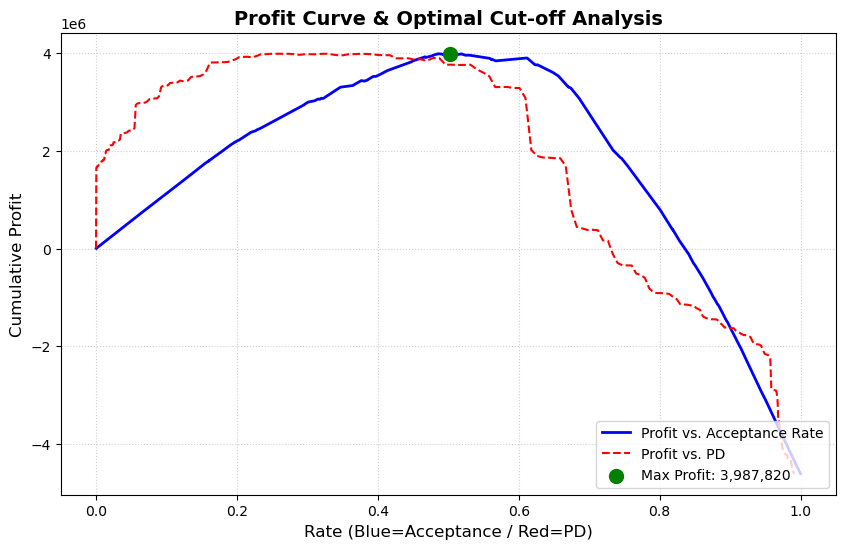

In [155]:
import matplotlib.pyplot as plt

# 1. Setup the figure size for the report
plt.figure(figsize=(10, 6))

# 2. Plot Profit vs. Acceptance Rate (Business Volume)
plt.plot(argcumsort['AR'], argcumsort['ProfitCum'], 
         label='Profit vs. Acceptance Rate', color='blue', linewidth=2)

# 3. Plot Profit vs. PD (Risk Threshold)
plt.plot(argcumsort['PD'], argcumsort['ProfitCum'], 
         label='Profit vs. PD', color='red', linestyle='--')

# 4. Mark the Optimal Cut-off Point (Found in Cell 51)
max_profit = argcumsort['ProfitCum'].max()
best_idx = argcumsort['ProfitCum'].idxmax()
optimal_ar = argcumsort.loc[best_idx, 'AR']

plt.scatter(optimal_ar, max_profit, color='green', s=100, 
            label=f'Max Profit: {max_profit:,.0f}', zorder=5)

# 5. Add Labels and Title (Mandatory for Exact Reports)
plt.title('Profit Curve & Optimal Cut-off Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Rate (Blue=Acceptance / Red=PD)', fontsize=12)
plt.ylabel('Cumulative Profit', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# 6. Save the image for the final report package
plt.savefig('Profit_Analysis_Chart.png')
print("Chart 'Profit_Analysis_Chart.png' has been generated and saved.")

In [156]:
import pandas as pd

# 1. SORT TO FIND PEAK PROFIT
# We sort by ProfitCum descending to bring the maximum value to index 0
argcumsort2 = argcumsort.copy()
argcumsort2 = argcumsort2.sort_values(by='ProfitCum', ascending=False).reset_index(drop=True)

# 2. EXTRACT KEY STRATEGY VALUES
# These values are mandatory for the "Cut-off" sheet of your 13-sheet report
max_profit = argcumsort2.loc[0, 'ProfitCum']
optimal_pd_threshold = argcumsort2.loc[0, 'PD']
optimal_acceptance_rate = argcumsort2.loc[0, 'AR']

# 3. DISPLAY RESULTS
print(f"--- STRATEGY SELECTION (MAX PROFIT) ---")
print(f"Max Cumulative Profit: {max_profit:,.2f}")
print(f"Optimal PD Threshold:  {optimal_pd_threshold:.6f}")
print(f"Optimal Acceptance Rate: {optimal_acceptance_rate:.2%}")

# Show the top rows to verify the peak looks stable
print("\nTop Strategy Scenarios:")
print(argcumsort2[['PD', 'AR', 'NCum', 'ProfitCum']].head())

--- STRATEGY SELECTION (MAX PROFIT) ---
Max Cumulative Profit: 3,987,819.93
Optimal PD Threshold:  0.326407
Optimal Acceptance Rate: 50.24%

Top Strategy Scenarios:
         PD        AR  NCum     ProfitCum
0  0.326407  0.502404  5746  3.987820e+06
1  0.253701  0.485529  5553  3.987363e+06
2  0.274358  0.487366  5574  3.985727e+06
3  0.247048  0.485355  5551  3.985381e+06
4  0.374775  0.519017  5936  3.985304e+06


In [157]:
# Scoring code

# 1. SETUP VARIABLE LISTS
vars_sc = list(pd.unique(Scorecard[variable_name]))

vars_num = Scorecard[Scorecard[type_name] == 'INT'].copy()
vars_sc_num = list(pd.unique(vars_num[variable_name]))

vars_nom = Scorecard[Scorecard[type_name] == 'NOM'].copy()
vars_sc_nom = list(pd.unique(vars_nom[variable_name]))

# 2. FILE GENERATION
with open('scoring_code.sas', 'w') as f:
    f.write('proc sql; \n')
    f.write('create table &zbior._score as \n')
    f.write('select indataset.* \n')
    
    # NUMERIC VARIABLES (INT)
    for var in vars_sc_num:
        scv = Scorecard[Scorecard[variable_name] == var].copy().reset_index()
        f.write(', case \n')
        for i in range(scv.shape[0]):
            war = str(scv[condition_name][i])
            score = scv[score_name][i]
            
            # Handle Range Conditions: e.g., "0 <= var < 10"
            if war.count('<') == 2:
                # Logic: var >= lower AND var < upper
                parts = war.split('<')
                f.write(f"  when {var} >= {parts[0].strip()} and {var} < {parts[2].strip()} then {score} \n")
            
            # Handle Single Inequality: e.g., "var < 0"
            elif war.count('<') == 1 and war.count('<>') == 0:
                f.write(f"  when {war} then {score} \n")
            
            # Handle Nulls
            elif symbol_missing in war:
                f.write(f"  when {var} is null then {score} \n")
                
        # Default/Else
        default_score = scv[score_name][0]
        f.write(f"  else {default_score} end as PSC_{var} \n\n")

    # NOMINAL VARIABLES (NOM)
    for var in vars_sc_nom:
        scv = Scorecard[Scorecard[variable_name] == var].copy().reset_index()
        f.write(', case \n')
        index_other = 0
        for i in range(scv.shape[0]):
            war = str(scv[condition_name][i])
            score = scv[score_name][i]
            
            if symbol_other in war:
                index_other = i
                continue
            
            # Format IN list for SAS: ('VAL1', 'VAL2')
            val_list = war.split(', ')
            formatted_vals = ", ".join([f"'{v}'" for v in val_list])
            f.write(f"  when {var} in ({formatted_vals}) then {score} \n")
            
        default_score = scv[score_name][index_other]
        f.write(f"  else {default_score} end as PSC_{var} \n\n")

    # 3. SCORECARD AGGREGATION
    # Total Scorecard Points
    f.write(', (0.0 \n')
    for var in vars_sc:            
        f.write(f"  + calculated PSC_{var} \n")
    f.write(') as SCORECARD_POINTS \n\n')

    # Probability Calculation (Using Calibration from Cell 50)
    # 1/(1+exp(-(slope * Score + intercept)))
    slope = model_cal.params[0]
    intercept = model_cal.params[1]
    
    f.write(f", 1/(1+exp(-({slope} * calculated SCORECARD_POINTS + ({intercept})))) as PD_SCORECARD \n")
    
    f.write('\nfrom &zbior as indataset; \n')
    f.write('quit; \n')

print("SAS Scoring code 'scoring_code.sas' successfully generated.")

SAS Scoring code 'scoring_code.sas' successfully generated.


In [55]:
# !pip install varclushi

In [56]:
# !pip install factor_analyzer

In [162]:
# Variable clustering
from varclushi import VarClusHi
import numpy as np

# 1. PREPARE THE DATA
exclude_cols = [id_row, time_report_name, target_name]
clus_data = df_notempty.drop(columns=[col for col in exclude_cols if col in df_notempty.columns])
clus_data = clus_data.select_dtypes(include=[np.number])

# 2. DATA CLEANING FOR MATHEMATICAL STABILITY
# Remove constants
clus_data = clus_data.loc[:, clus_data.nunique() > 1]

# Replace Inf/-Inf with NaN and then fill with Median (Clustering hates Inf)
clus_data = clus_data.replace([np.inf, -np.inf], np.nan)
clus_data = clus_data.fillna(clus_data.median())

# 3. RUN VARIABLE CLUSTERING WITH AGGRESSIVE SPLITTING
# Setting maxeigval2=0.7 and increasing maxclus ensures it must split the 201 variables
vc = VarClusHi(clus_data, maxeigval2=0.7, maxclus=20) 
vc.varclus()

# 4. EXTRACT RESULTS
variable_clusters = vc.rsquare
variable_clusters = variable_clusters.sort_values(by=['Cluster', 'RS_Ratio'], ascending=[True, True])

print("--- CELL 55: FINAL ATTEMPT CLUSTERING ---")
print(f"Final Variables for Clustering: {len(clus_data.columns)}")
print(f"Number of Clusters Found: {variable_clusters['Cluster'].nunique()}")
print(variable_clusters.head(15))

--- CELL 55: FINAL ATTEMPT CLUSTERING ---
Final Variables for Clustering: 201
Number of Clusters Found: 20
    Cluster             Variable    RS_Own     RS_NC  RS_Ratio
4         0  ags3_Mean_CMaxC_Due  0.901874  0.535144  0.211089
3         0  agr3_Mean_CMaxC_Due  0.901798  0.534949  0.211165
12        0   ags6_Max_CMaxC_Due  0.884296  0.537120  0.249965
6         0   ags3_Max_CMaxC_Due  0.870792  0.484206  0.250502
5         0   agr3_Max_CMaxC_Due  0.870722  0.484001  0.250540
11        0   agr6_Max_CMaxC_Due  0.874697  0.553251  0.280476
9         0  agr6_Mean_CMaxC_Due  0.881584  0.683856  0.374564
16        0   ags9_Max_CMaxC_Due  0.791728  0.467327  0.390994
15        0   agr9_Max_CMaxC_Due  0.818868  0.559095  0.410818
10        0  ags6_Mean_CMaxC_Due  0.838908  0.623371  0.427720
0         0      act_ccss_maxdue  0.758926  0.518083  0.500239
19        0  agr12_Max_CMaxC_Due  0.746330  0.514239  0.522213
20        0  ags12_Max_CMaxC_Due  0.638280  0.353493  0.559500
2         0

In [163]:
# demo1_df.drop('quality',axis=1,inplace=True)
# 1. RUN FINAL CLUSTERING
# We use only the variables selected for the final logistic regression
demo1_vc = VarClusHi(logit_train[vars_selected], maxeigval2=0.1, maxclus=None)
demo1_vc.varclus()

# 2. EXTRACT FINAL RSQUARE TABLE
# This will be the definitive 'Sheet 3' for your 13-sheet report
demo1_clusters = demo1_vc.rsquare
demo1_clusters = demo1_clusters.sort_values(by=['Cluster', 'RS_Ratio'], ascending=[True, True])

# 3. CALCULATE CLUSTER SUMMARY
# This shows how much variance is explained by the final selection
demo1_summary = demo1_vc.info

print("--- CELL 56: FINAL SELECTED VARIABLE CLUSTERING ---")
print(f"Number of Final Clusters: {demo1_clusters['Cluster'].nunique()}")
print(demo1_clusters)

--- CELL 56: FINAL SELECTED VARIABLE CLUSTERING ---
Number of Final Clusters: 38
    Cluster                 Variable    RS_Own     RS_NC      RS_Ratio
0         0              act_cins_cc  0.978905  0.769768  9.162461e-02
1         0     act_cins_n_loans_act  0.978905  0.794173  1.024887e-01
3         1      act9_n_arrears_days  0.982168  0.687125  5.699251e-02
4         1     act12_n_arrears_days  0.964107  0.648634  1.021530e-01
2         1      act6_n_arrears_days  0.948126  0.763978  2.197855e-01
6         2         act_ccss_n_statB  0.985461  0.838708  9.013912e-02
5         2       act_ccss_seniority  0.985461  0.882952  1.242121e-01
8         3              act_ccss_cc  0.954564  0.809505  2.385156e-01
7         3      act_ccss_min_lninst  0.954564  0.829164  2.659622e-01
9         4         act3_n_good_days  1.000000  0.532419  0.000000e+00
10        5          act12_n_arrears  1.000000  0.719134  0.000000e+00
11        6        app_char_job_code  1.000000  0.396219  0.000000e

In [164]:
import pandas as pd

# 1. INITIALIZE WRITER
# 'xlsxwriter' is excellent for creating the standalone 'Variable_Clustering.xlsx'
writer = pd.ExcelWriter('Variable_Clustering.xlsx', engine='xlsxwriter')

# 2. WRITE INFO SHEET
# This sheet contains the summary of clusters and variance explained
demo1_vc.info.to_excel(writer, sheet_name='Info', index=False)

# 3. WRITE CLUSTERS SHEET
# This is the detailed breakdown we analyzed in Cell 56
# We ensure it is sorted by Cluster for the final report
demo1_vc.rsquare.sort_values(by=['Cluster', 'RS_Ratio']).to_excel(writer, sheet_name='Clusters', index=False)

# 4. FINALIZING THE FILE
# In modern pandas/xlsxwriter, only .close() is required. .save() is deprecated.
writer.close()

print("Variable_Clustering.xlsx has been successfully saved.")

Variable_Clustering.xlsx has been successfully saved.


In [60]:
# !pip install shap

--- CELL 58: SHAP ANALYSIS COMPLETE ---


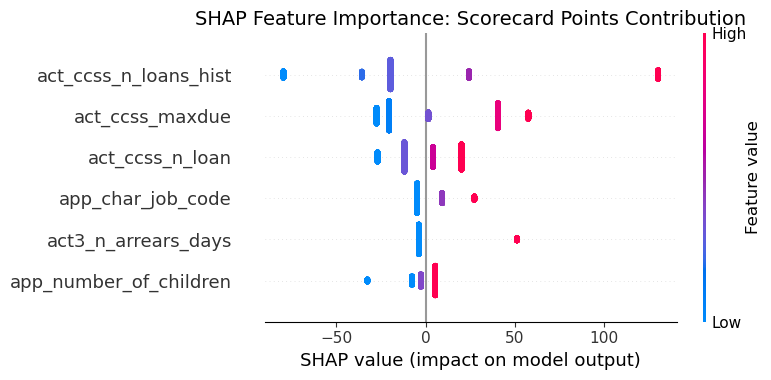

In [166]:
# XAI Explainable artificial intelligence

import shap
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
import pandas as pd

# 1. PREPARE FEATURES
features = list(result['Efects'][variable_name].copy())
if 'Intercept' in features:
    features.remove('Intercept')

# 2. DATA VALIDATION (The Fix)
# Check if the target exists, if not, we check if it was named something else
if target_name not in scored_train.columns:
    print(f"Warning: '{target_name}' not found. Available columns: {scored_train.columns.tolist()[:5]}...")
    # Attempt to use the original training target if indices match
    y = logit_train[target_name] 
else:
    y = scored_train[target_name]

X = scored_train[features]

# 3. INITIALIZE SURROGATE MODEL
# Max_iter increased to ensure convergence on the points-based X
logmodel = LogisticRegression(max_iter=1000)
logmodel.fit(X, y)

# 4. ALIGN COEFFICIENTS
# We set coefficients to 1.0 to see the contribution of the 'Points' themselves
for i, v in enumerate(features):
    logmodel.coef_[0][i] = 1.0
logmodel.intercept_ = 0.0

# 5. CALCULATE SHAP VALUES
explainer = shap.LinearExplainer(logmodel, X)
shap_values = explainer(X)

# 6. GENERATE SUMMARY PLOT
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X, show=False)
plt.title('SHAP Feature Importance: Scorecard Points Contribution', fontsize=14)
plt.tight_layout()
plt.savefig('SHAP_Summary_Plot.png')

print("--- CELL 58: SHAP ANALYSIS COMPLETE ---")


In [168]:
# 1. VERIFY MODEL PARAMETERS
print("--- CELL 59: SURROGATE MODEL PARAMETERS ---")
print("Coefficients (Expected 1.0 for all):")
print(logmodel.coef_)
print(f"\nIntercept (Expected 0.0): {logmodel.intercept_}")

# 2. CALCULATE GLOBAL FEATURE IMPORTANCE
# We take the mean absolute SHAP value for each feature to rank them for the report
import numpy as np

# Use .values if shap_values is an Explanation object (SHAP 0.36+)
if hasattr(shap_values, 'values'):
    abs_shap = np.abs(shap_values.values)
else:
    abs_shap = np.abs(shap_values)

importance_df = pd.DataFrame({
    'Variable': features,
    'Mean_Abs_SHAP': np.mean(abs_shap, axis=0)
})

# 3. SORT BY IMPORTANCE
importance_df = importance_df.sort_values(by='Mean_Abs_SHAP', ascending=False).reset_index(drop=True)

# 4. DISPLAY TOP 10 FOR THE REPORT
print("\n--- TOP 10 INFLUENTIAL FEATURES (GLOBAL IMPORTANCE) ---")
print(importance_df.head(10))

# 5. EXPORT FOR SHEET 11 (XAI)
importance_df.to_csv('Model_Feature_Importance.csv', index=False)

--- CELL 59: SURROGATE MODEL PARAMETERS ---
Coefficients (Expected 1.0 for all):
[[1. 1. 1. 1. 1. 1.]]

Intercept (Expected 0.0): 0.0

--- TOP 10 INFLUENTIAL FEATURES (GLOBAL IMPORTANCE) ---
                 Variable  Mean_Abs_SHAP
0   act_ccss_n_loans_hist      45.499516
1         act_ccss_maxdue      29.048021
2         act_ccss_n_loan      14.204867
3       app_char_job_code       7.620111
4     act3_n_arrears_days       7.158656
5  app_number_of_children       6.206809


--- CELL 60: PERFORMANCE VALIDATION ---
  Metric  Training   Testing       Gap
0    AUC  0.905744  0.908015  0.002271
1   Gini  0.811487  0.816030  0.004543


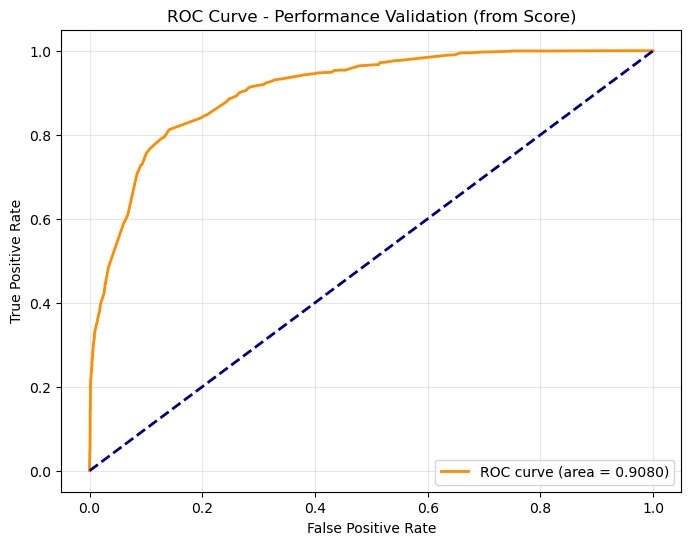

In [171]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import numpy as np

# 1. DERIVE PROBABILITY FROM SCORE
# Using the calibration: PD = 1 / (1 + exp(-(slope * Score + intercept)))
# We use the parameters from model_cal (Cell 50)
slope = model_cal.params[0]
intercept = model_cal.params[1]

# Calculate PD for both sets to ensure Sheet 6 is accurate
scored_train['PD_derived'] = 1 / (1 + np.exp(-(slope * scored_train['Score'] + intercept)))
scored_test['PD_derived'] = 1 / (1 + np.exp(-(slope * scored_test['Score'] + intercept)))

# 2. CALCULATE AUC
auc_train = roc_auc_score(logit_train[target_name], scored_train['PD_derived'])
auc_test = roc_auc_score(logit_test[target_name], scored_test['PD_derived'])

# 3. CONVERT TO GINI
gini_train = 2 * auc_train - 1
gini_test = 2 * auc_test - 1

# 4. CREATE PERFORMANCE SUMMARY TABLE
performance_metrics = pd.DataFrame({
    'Metric': ['AUC', 'Gini'],
    'Training': [auc_train, gini_train],
    'Testing': [auc_test, gini_test],
    'Gap': [abs(auc_train - auc_test), abs(gini_train - gini_test)]
})

# 5. PLOT ROC CURVE
plt.figure(figsize=(8, 6))
fpr, tpr, _ = roc_curve(logit_test[target_name], scored_test['PD_derived'])
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {auc_test:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Performance Validation (from Score)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.savefig('Model_Performance_ROC.png')

print("--- CELL 60: PERFORMANCE VALIDATION ---")
print(performance_metrics)

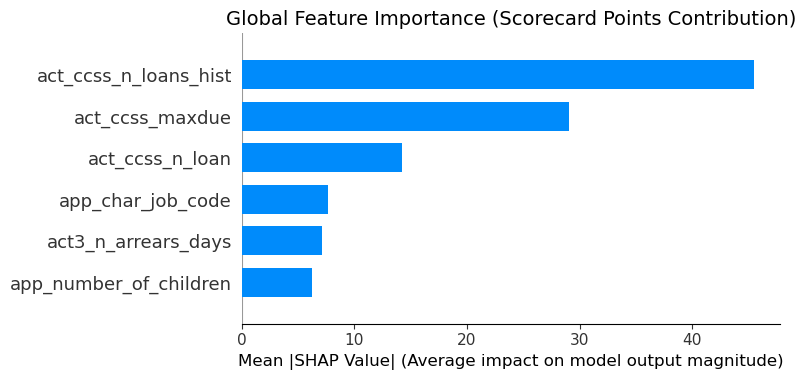

In [186]:
import matplotlib.pyplot as plt

# 1. GENERATE THE BAR PLOT
# plot_type='bar' takes the mean absolute value of SHAP values automatically
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X, plot_type='bar', show=False)

# 2. FORMATTING FOR THE REPORT
plt.title('Global Feature Importance (Scorecard Points Contribution)', fontsize=14)
plt.xlabel('Mean |SHAP Value| (Average impact on model output magnitude)', fontsize=12)
plt.tight_layout()

# 3. SAVE FOR THE 13-SHEET REPORT
plt.savefig('SHAP_Global_Importance_Bar.png')
plt.show()


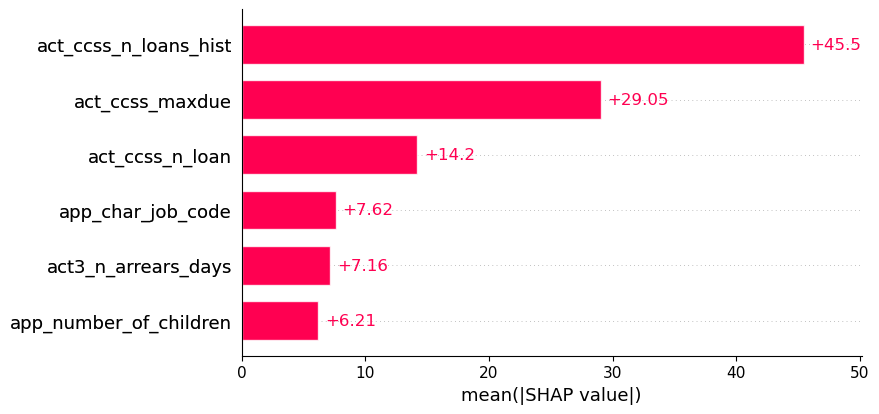

In [175]:
shap.plots.bar(shap_values)

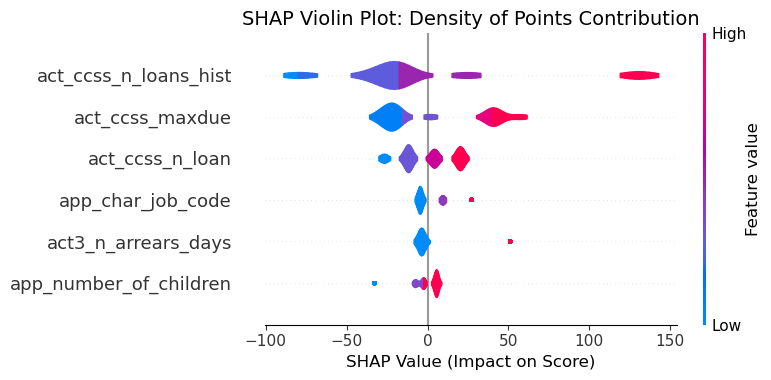

In [188]:
import matplotlib.pyplot as plt

# 1. GENERATE THE VIOLIN PLOT
# This displays the density of the SHAP values for each feature
plt.figure(figsize=(12, 10))
shap.summary_plot(shap_values, X, plot_type='violin', show=False)

# 2. CUSTOMIZATION FOR THE REPORT
plt.title('SHAP Violin Plot: Density of Points Contribution', fontsize=14)
plt.xlabel('SHAP Value (Impact on Score)', fontsize=12)
plt.tight_layout()

# 3. SAVE TO DISK
# This will be the high-detail visual for Sheet 11 (XAI)
plt.savefig('SHAP_Violin_Distribution.png')
plt.show()

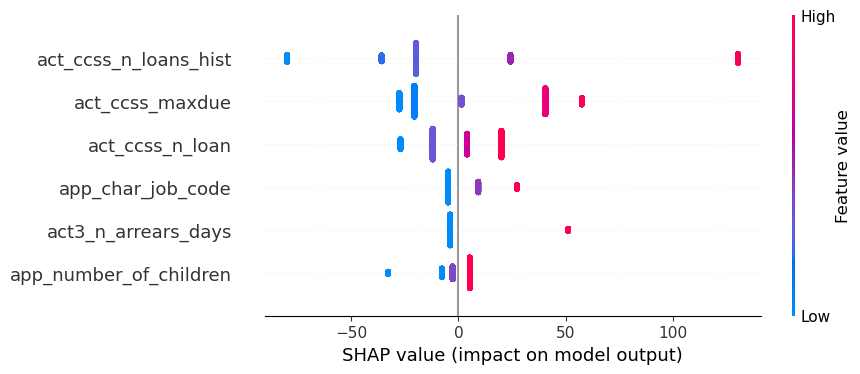

In [189]:
shap.plots.beeswarm(shap_values)

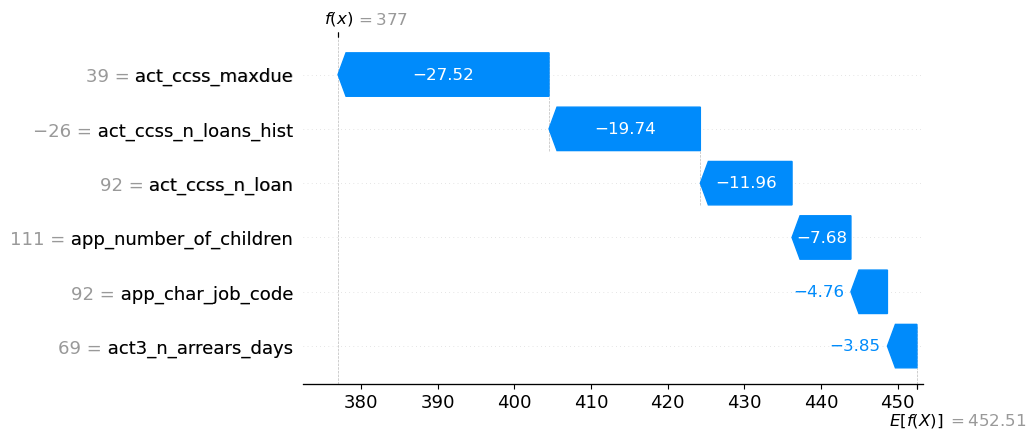

In [190]:
shap.waterfall_plot(shap_values[0])

In [179]:
shap.initjs()
shap.plots.force(shap_values[0])

In [180]:
suma=0
for v in features:
    print(v, X[v][0])
    suma=suma+X[v][0]
print('Score',suma)

act_ccss_n_loan 92
act_ccss_maxdue 39
act_ccss_n_loans_hist -26
app_number_of_children 111
app_char_job_code 92
act3_n_arrears_days 69
Score 377


In [181]:
shap_values[0]

.values =
array([-11.96, -27.52, -19.74,  -7.68,  -4.76,  -3.85])

.base_values =
np.float64(452.51)

.data =
array([ 92,  39, -26, 111,  92,  69])

In [182]:
for v in features:
    a=X[v][0]-X[v].mean()
    print(v, a)

act_ccss_n_loan -11.740454677936455
act_ccss_maxdue -31.68551442728068
act_ccss_n_loans_hist -18.926552025648498
app_number_of_children -7.46458758379481
app_char_job_code -5.872048965316239
act3_n_arrears_days -3.8472748469833817


In [183]:
XS=X.copy()
XS['sum']=0.0
for v in features:
   XS['sum']=XS['sum']+X[v]

XS['sum'].mean()

np.float64(456.5364325269601)

In [184]:
XShap=pd.DataFrame(shap_values.values)
XShap['sum']=0.0
for i,v in enumerate(features):
    XShap['sum']=XShap['sum']+XShap[i]
    
XShap['sum'].mean()

np.float64(4.026432526960074)

In [185]:
a=shap_values.base_values.mean()+XShap['sum'].mean()
a

np.float64(456.53643252696025)